# Aircraft Engine Predictive Maintenance — Data Analysis & Feature Engineering
### NASA C-MAPSS Turbofan Engine Degradation Dataset (FD001)

**Task 2 — data understanding, cleaning, EDA, feature engineering and leakage-aware preprocessing.**
This notebook stops at an ML-ready dataset. No model is trained here.

---

### Summary of results

| | |
|---|---|
| **Data** | 100 run-to-failure training engines (20,631 cycles) and 100 truncated test engines; 21 sensors and 3 settings |
| **Quality** | Structurally clean: no missing values, duplicates or invalid readings. 7 constant columns dropped |
| **Outliers** | 11.8% of rows exceed IQR fences, but 61% of these fall in the final 10% of life, in each sensor's wear direction. They are degradation, not errors. **No rows removed** |
| **Operating conditions** | One regime; the settings explain < 0.04% of any sensor's variance. No normalisation needed |
| **Degradation** | Shared, non-linear pattern, visible ~120–160 cycles before failure; strongest in `Ps30`, `T50`, `phi`, `P30` |
| **Features** | 57 leakage-tested temporal features built per engine → **17 selected** (health index, 12 baseline deltas, 3 smoothed levels, cycle) |
| **Evidence** | Engine-grouped CV diagnostic: raw sensors RMSE 16.7 → selected features 9.0. A random row split would have reported 5.2 (42% optimistic) |
| **Target** | `RUL_capped = min(RUL, 125)` recommended; uncapped `RUL` retained |
| **QA** | 51/51 automated checks pass on the saved files |

---

## 0. Problem framing

**The real-world problem.** A turbofan engine wears down gradually. If an airline replaces parts on a fixed schedule, it throws away useful life. If it waits for a failure, the failure happens in service. *Predictive maintenance* uses sensor data to estimate how much life an engine has left, so maintenance can be planned just before it is needed.

**The dataset.** NASA's C-MAPSS simulator was used to generate run-to-failure histories for a fleet of engines of the same type (Saxena et al., 2008). FD001 is the simplest of the four subsets:

| Property | FD001 (from `readme.txt`) |
|---|---|
| Training trajectories | 100 engines, each run until failure |
| Test trajectories | 100 engines, each stopped some time *before* failure |
| Operating conditions | One (sea level) |
| Fault modes | One (HPC — high-pressure compressor — degradation) |

Each row is a single snapshot taken once per flight cycle. Each engine starts with an unknown amount of initial wear and manufacturing variation, and the readme notes that *"the data is contaminated with sensor noise"*.

**Target — Remaining Useful Life (RUL).** The number of cycles an engine will still run before it fails. The dataset does not contain RUL for the training engines. It has to be derived from the trajectories (Section 5).

### How each Task 2 requirement is addressed

| Requirement | Section |
|---|---|
| Data understanding | 2 — ingestion & data dictionary |
| Data cleaning, missing values, duplicates | 3 — data-quality audit |
| Outlier analysis | 4 |
| Target definition | 5 — RUL engineering |
| Meaningful EDA | 6, 7 |
| Feature engineering & selection | 8, 9 |
| Categorical encoding | 10 |
| Numerical scaling | 11 |
| Reasoning behind decisions | Every section ends with a **Decision** |
| Leakage prevention | 12, plus checks inside 8 and 11 |

### Dataset-specific risks identified up front

| Risk | Why it matters here |
|---|---|
| **Temporal leakage** | Rows are time-ordered. A feature built from future cycles would describe the engine's future, which is not available at prediction time. |
| **Engine / entity leakage** | Cycles from the same engine are highly correlated. If one engine's rows appear in both training and validation, validation scores look better than they really are. |
| **Target leakage** | RUL is computed from an engine's *final* cycle. Any feature derived from the total lifetime would give away the answer. |
| **Near-constant sensors** | With a single operating condition, some sensors may barely move. They add dimensions without adding information. |
| **Redundant sensors** | Physically coupled quantities (e.g. physical and corrected speeds) may carry the same signal. |
| **Operating-condition effects** | In multi-condition subsets, the settings shift sensor levels. FD001 has only one condition, and this needs to be verified rather than assumed. |
| **Sensor noise** | Single readings are noisy, so degradation trends may only become visible after smoothing. |
| **Inappropriate outlier removal** | Extreme readings near failure are likely the degradation signal itself. Deleting them would remove exactly the information we need. |

## 1. Setup

All paths are relative to the project root, so the notebook runs from a fresh clone once the raw files are in `data/raw/` (see README).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Resolve the project root whether the notebook is run from notebooks/ or the repo root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (PROCESSED_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SUBSET = "FD001"
RANDOM_STATE = 42

In [2]:
# One restrained chart style for every figure: recessive grid and axes, text in neutral ink,
# a fixed colour order (series colours follow the entity, never its rank).
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
NEUTRAL = "#a3a29c"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 1.6, "legend.frameon": False, "legend.fontsize": 9,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURE_DIR / f"{name}.png")

## 2. Data ingestion & data dictionary

### 2.1 Verify the raw file format before parsing

**What / why.** The readme says the files have *"26 columns of numbers, separated by spaces"*. Before relying on that, we check every raw line. Whitespace issues are a common cause of phantom `NaN` columns in this dataset.

In [3]:
def inspect_raw_format(path: Path) -> dict:
    # Field counts per line and trailing-whitespace usage, read from the untouched text file.
    lines = path.read_text().splitlines()
    field_counts = pd.Series([len(line.split()) for line in lines])
    return {
        "file": path.name,
        "lines": len(lines),
        "fields_per_line": sorted(field_counts.unique().tolist()),
        "lines_with_trailing_space": sum(line != line.rstrip() for line in lines),
    }


raw_files = {
    "train": RAW_DIR / f"train_{SUBSET}.txt",
    "test": RAW_DIR / f"test_{SUBSET}.txt",
    "rul": RAW_DIR / f"RUL_{SUBSET}.txt",
}
pd.DataFrame([inspect_raw_format(path) for path in raw_files.values()])

,file,lines,fields_per_line,lines_with_trailing_space
0,train_FD001.txt,20631,[26],20631
1,test_FD001.txt,13096,[26],13096
2,RUL_FD001.txt,100,[1],100


**Result and interpretation.** Every line in the train and test files has exactly 26 whitespace-separated values, and every line ends with trailing spaces. If we parsed on a single space character, those trailing spaces would create empty columns that look like missing data but are not. We therefore parse on any run of whitespace (`sep=r"\s+"`) and check the column count afterwards.

> **Note on the readme.** The readme lists the columns as running up to *"sensor measurement 26"*. That is a typo: the 26 columns are 2 identifiers, 3 operating settings and **21 sensors**, which matches the 21 sensed outputs listed in Table 2 of the paper.

### 2.2 Meaningful column names

**Where the names come from.** The sensor symbols and units come from **Table 2 of Saxena et al. (2008)**, which is included in the NASA download. The paper lists the 21 sensed outputs in order. Mapping them to sensor columns 1–21 in that order is the standard interpretation, but the paper does not state it explicitly, so we treat it as a documented assumption and check it against the data below.

Neither the readme nor the paper says what the three **operational settings** physically are. We keep them as anonymous `op_setting_1..3` rather than guess.

In [4]:
# (symbol, description, units) — Saxena et al. (2008), Table 2, in listed order.
SENSOR_METADATA = [
    ("T2",        "Total temperature at fan inlet",       "°R"),
    ("T24",       "Total temperature at LPC outlet",      "°R"),
    ("T30",       "Total temperature at HPC outlet",      "°R"),
    ("T50",       "Total temperature at LPT outlet",      "°R"),
    ("P2",        "Pressure at fan inlet",                "psia"),
    ("P15",       "Total pressure in bypass duct",        "psia"),
    ("P30",       "Total pressure at HPC outlet",         "psia"),
    ("Nf",        "Physical fan speed",                   "rpm"),
    ("Nc",        "Physical core speed",                  "rpm"),
    ("epr",       "Engine pressure ratio (P50/P2)",       "–"),
    ("Ps30",      "Static pressure at HPC outlet",        "psia"),
    ("phi",       "Ratio of fuel flow to Ps30",           "pps/psi"),
    ("NRf",       "Corrected fan speed",                  "rpm"),
    ("NRc",       "Corrected core speed",                 "rpm"),
    ("BPR",       "Bypass ratio",                         "–"),
    ("farB",      "Burner fuel-air ratio",                "–"),
    ("htBleed",   "Bleed enthalpy",                       "–"),
    ("Nf_dmd",    "Demanded fan speed",                   "rpm"),
    ("PCNfR_dmd", "Demanded corrected fan speed",         "rpm"),
    ("W31",       "HPT coolant bleed",                    "lbm/s"),
    ("W32",       "LPT coolant bleed",                    "lbm/s"),
]

ID_COLUMNS = ["unit_id", "cycle"]
SETTING_COLUMNS = ["op_setting_1", "op_setting_2", "op_setting_3"]
SENSOR_COLUMNS = [symbol for symbol, _, _ in SENSOR_METADATA]
RAW_COLUMNS = ID_COLUMNS + SETTING_COLUMNS + SENSOR_COLUMNS
assert len(RAW_COLUMNS) == 26

In [5]:
def load_trajectories(path: Path) -> pd.DataFrame:
    # Load a C-MAPSS train/test file with named columns and integer identifiers.
    df = pd.read_csv(path, sep=r"\s+", header=None, names=RAW_COLUMNS)
    if df.shape[1] != len(RAW_COLUMNS) or df.isna().all(axis=0).any():
        raise ValueError(f"{path.name}: unexpected column layout")
    return df.astype({"unit_id": "int32", "cycle": "int32"})


train_raw = load_trajectories(raw_files["train"])
test_raw = load_trajectories(raw_files["test"])
test_true_rul = (
    pd.read_csv(raw_files["rul"], sep=r"\s+", header=None, names=["true_rul"])
    .assign(unit_id=lambda d: np.arange(1, len(d) + 1, dtype="int32"))
    [["unit_id", "true_rul"]]
)

print("train:", train_raw.shape, "| test:", test_raw.shape, "| test RUL labels:", test_true_rul.shape)
train_raw.head()

train: (20631, 26) | test: (13096, 26) | test RUL labels: (100, 2)


,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,T50,P2,P15,P30,Nf,Nc,epr,Ps30,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,"1,589.7000","1,400.6000",14.6200,21.6100,554.3600,"2,388.0600","9,046.1900",1.3000,47.4700,521.6600,"2,388.0200","8,138.6200",8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,"1,591.8200","1,403.1400",14.6200,21.6100,553.7500,"2,388.0400","9,044.0700",1.3000,47.4900,522.2800,"2,388.0700","8,131.4900",8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,"1,587.9900","1,404.2000",14.6200,21.6100,554.2600,"2,388.0800","9,052.9400",1.3000,47.2700,522.4200,"2,388.0300","8,133.2300",8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,"1,582.7900","1,401.8700",14.6200,21.6100,554.4500,"2,388.1100","9,049.4800",1.3000,47.1300,522.8600,"2,388.0800","8,133.8300",8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,"1,582.8500","1,406.2200",14.6200,21.6100,554.0000,"2,388.0600","9,055.1500",1.3000,47.2800,522.1900,"2,388.0400","8,133.8000",8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


**Checking the sensor-name mapping against the data.** If the Table-2 order is correct, the column labelled `T2` (fan-inlet temperature) should equal the ambient temperature of a sea-level operating condition. The ISA sea-level standard temperature is 15 °C = 288.15 K = **518.67 °R**.

In [6]:
train_raw[["T2", "P2"]].agg(["min", "max", "nunique"])

,T2,P2
min,518.6700,14.6200
max,518.6700,14.6200
nunique,1.0000,1.0000


**Result.** `T2` takes a single value, 518.67 °R, the ISA sea-level standard temperature. `P2` is also constant, at 14.62 psia, close to the sea-level standard of 14.70 psia (the paper does not explain the small difference, so we do not speculate about it). Both match the readme's *"ONE (Sea Level)"* condition and support the Table-2 mapping. The mapping is still not proven for every column, so the README lists it as an assumption.

### 2.3 Data dictionary

The dictionary records what each column *is* and what *role* it may play. Whether a candidate feature is actually kept is decided later (Section 9) from evidence. `RUL` is included even though it is not in the raw files, because it is the derived target.

In [7]:
def build_data_dictionary(df: pd.DataFrame) -> pd.DataFrame:
    rows = [
        ("unit_id", "Engine identifier (one trajectory per engine)", "–", "identifier", True, False, True),
        ("cycle", "Time index: operational cycle number within an engine", "cycles", "time index", True, True, True),
    ]
    rows += [
        (col, "Operational setting (physical meaning not documented in readme or paper)", "–",
         "operating setting", False, True, False)
        for col in SETTING_COLUMNS
    ]
    rows += [
        (symbol, description, units, "sensor measurement", False, True, False)
        for symbol, description, units in SENSOR_METADATA
    ]
    dictionary = pd.DataFrame(
        rows,
        columns=["column", "meaning", "units", "role", "is_identifier", "feature_candidate", "target_related"],
    )
    dictionary.insert(1, "dtype", dictionary["column"].map(df.dtypes.astype(str)))
    target_row = pd.DataFrame([{
        "column": "RUL", "dtype": "int (derived)", "meaning": "Remaining useful life = engine's last cycle − current cycle",
        "units": "cycles", "role": "target (derived, Section 5)", "is_identifier": False,
        "feature_candidate": False, "target_related": True,
    }])
    return pd.concat([dictionary, target_row], ignore_index=True)


data_dictionary = build_data_dictionary(train_raw)
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)
data_dictionary

,column,dtype,meaning,units,role,is_identifier,feature_candidate,target_related
0,unit_id,int32,Engine identifier (one trajectory per engine),–,identifier,True,False,True
1,cycle,int32,Time index: operational cycle number within an engine,cycles,time index,True,True,True
2,op_setting_1,float64,Operational setting (physical meaning not documented in readme or paper),–,operating setting,False,True,False
3,op_setting_2,float64,Operational setting (physical meaning not documented in readme or paper),–,operating setting,False,True,False
4,op_setting_3,float64,Operational setting (physical meaning not documented in readme or paper),–,operating setting,False,True,False
5,T2,float64,Total temperature at fan inlet,°R,sensor measurement,False,True,False
6,T24,float64,Total temperature at LPC outlet,°R,sensor measurement,False,True,False
7,T30,float64,Total temperature at HPC outlet,°R,sensor measurement,False,True,False
8,T50,float64,Total temperature at LPT outlet,°R,sensor measurement,False,True,False
9,P2,float64,Pressure at fan inlet,psia,sensor measurement,False,True,False


**Notes on the role flags**

- `unit_id` groups rows into trajectories. It is **never** a model input: the engine's ID number says nothing physical about its health, and a model could memorise IDs.
- `cycle` is marked *target-related* because RUL is calculated from it. Using the **current** cycle as a feature is legitimate, since an operator knows how many flights an engine has flown. Using an engine's **maximum** cycle is not: it is only known once the engine has failed, and it would leak the target.

### 2.4 Dataset overview

In [8]:
def lifetime_summary(df: pd.DataFrame) -> pd.Series:
    # Observed trajectory length per engine.
    return df.groupby("unit_id")["cycle"].max()


train_life = lifetime_summary(train_raw)
test_observed = lifetime_summary(test_raw)


def describe_split(df: pd.DataFrame, lengths: pd.Series) -> dict:
    return {
        "rows": f"{len(df):,}",
        "engines": f"{df['unit_id'].nunique()}",
        "operational settings": f"{len(SETTING_COLUMNS)}",
        "sensors": f"{len(SENSOR_COLUMNS)}",
        "cycles per engine — min": f"{lengths.min()}",
        "cycles per engine — median": f"{lengths.median():g}",
        "cycles per engine — max": f"{lengths.max()}",
        "memory (MB)": f"{df.memory_usage(deep=True).sum() / 1e6:.2f}",
    }


overview = pd.DataFrame({"train": describe_split(train_raw, train_life), "test": describe_split(test_raw, test_observed)})
overview

,train,test
rows,"20,631","13,096"
engines,100,100
operational settings,3,3
sensors,21,21
cycles per engine — min,128,31
cycles per engine — median,199,133.5
cycles per engine — max,362,303
memory (MB),4.13,2.62


In [9]:
train_raw.dtypes.value_counts().rename("column count").to_frame()

,column count
float64,22
int32,2
int64,2


In [10]:
train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
unit_id,"20,631.0000",51.5066,29.2276,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,"20,631.0000",108.8079,68.8810,1.0000,52.0000,104.0000,156.0000,362.0000
op_setting_1,"20,631.0000",-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,"20,631.0000",0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,"20,631.0000",100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000
T2,"20,631.0000",518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700
T24,"20,631.0000",642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300
T30,"20,631.0000","1,590.5231",6.1311,"1,571.0400","1,586.2600","1,590.1000","1,594.3800","1,616.9100"
T50,"20,631.0000","1,408.9338",9.0006,"1,382.2500","1,402.3600","1,408.0400","1,414.5550","1,441.4900"
P2,"20,631.0000",14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200


In [11]:
# Test engines are cut off before failure; RUL_FD001 gives the remaining life after their last observed cycle.
test_true_rul["true_rul"].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
true_rul,100.0000,75.5200,41.7650,7.0000,32.7500,86.0000,112.2500,145.0000


### 2.5 Interpretation and decisions

**What this tells us**

- The training set covers **100 engines**, each run to failure, with **20,631 rows** in total. Lifetimes range from **128 to 362 cycles** (median 199), almost a threefold spread. So age alone cannot tell us how close an engine is to failure: an engine at cycle 130 may be about to fail, or may have more than 200 cycles left. Any useful signal has to come from the sensors.
- All 26 columns are numeric: 2 × `int32` identifiers, 22 × `float64`, and 2 × `int64` (`htBleed` and `Nf_dmd` are recorded as whole numbers). There are no object/string columns.
- In `describe()`, **`op_setting_3`, `T2`, `P2`, `epr`, `farB`, `Nf_dmd` and `PCNfR_dmd` show a standard deviation of 0.0000 at four decimals**, and `P15` (std 0.0014) and `op_setting_1/2` (values within ±0.009 of zero) barely move. This is only a first impression from rounded output. Section 3 checks it formally before any column is dropped.
- The **test set** has 100 truncated trajectories (31–303 observed cycles) and one true-RUL label per engine (7–145 cycles, mean 75.5). It is meant for evaluating a future model, not as extra training data.

**Decisions**

1. Parse with `sep=r"\s+"`, so the trailing whitespace cannot create phantom columns.
2. Use sensor symbols from Saxena et al. (2008), Table 2, as column names. Record the column-order mapping as a supported but explicit assumption.
3. **Keep the test set untouched** until the end. Every statistic, threshold and fitted transformation in this notebook comes from the **training engines only**. The test set is passed through the same pipeline only once the pipeline is fixed.
4. `unit_id` is used for grouping only and is never a feature.

## 3. Data-quality audit

**What / why.** Before any cleaning, we measure what is actually wrong with the data. Each check below is a question with a numeric answer. Treatments are chosen only for problems that actually exist. The test set gets the same structural checks, because a model would eventually be scored on it, but nothing is *fitted* on it.

### 3.1 Structural and validity checks

In [12]:
def structural_checks(df: pd.DataFrame) -> pd.Series:
    numeric = df.select_dtypes("number")
    cycles = df.groupby("unit_id")["cycle"]
    engines_with_gaps = ~(cycles.min().eq(1) & cycles.max().eq(cycles.count()))
    expected_order = df.sort_values(["unit_id", "cycle"]).index
    return pd.Series({
        "missing values": df.isna().sum().sum(),
        "fully duplicated rows": df.duplicated().sum(),
        "duplicate (unit_id, cycle) pairs": df.duplicated(["unit_id", "cycle"]).sum(),
        "duplicate sensor snapshots (ignoring cycle)": df.drop(columns="cycle").duplicated().sum(),
        "infinite values": np.isinf(numeric).sum().sum(),
        "non-numeric columns": df.shape[1] - numeric.shape[1],
        "engines with gaps or offsets in cycle numbering": engines_with_gaps.sum(),
        "rows out of (unit_id, cycle) order": (df.index != expected_order).sum(),
        # Every sensor is an absolute temperature, absolute pressure, speed, ratio or flow: all must be > 0.
        "non-positive sensor readings": (df[SENSOR_COLUMNS] <= 0).sum().sum(),
    }).astype(int)


quality_checks = pd.DataFrame({"train": structural_checks(train_raw), "test": structural_checks(test_raw)})
quality_checks

,train,test
missing values,0,0
fully duplicated rows,0,0
"duplicate (unit_id, cycle) pairs",0,0
duplicate sensor snapshots (ignoring cycle),0,0
infinite values,0,0
non-numeric columns,0,0
engines with gaps or offsets in cycle numbering,0,0
"rows out of (unit_id, cycle) order",0,0
non-positive sensor readings,0,0


**Result.** Every check returns **zero** in both splits:

- **No missing values were detected, so no imputation was performed.**
- **No duplicate rows or duplicate `(unit_id, cycle)` pairs exist, so no de-duplication was performed.** We also checked for identical sensor snapshots recorded under different cycle numbers (e.g. a copied row), and there are none.
- Every engine's cycles run 1, 2, 3, … without gaps, the rows are already in time order within each engine, and no physical sensor reading is zero or negative.

This is what a simulated dataset looks like: clean in its *structure*. The realistic difficulty lies in the *content*: sensor noise, uninformative channels and degradation signals that are easy to mistake for outliers. The rest of this section and Section 4 address that.

### 3.2 Constant and near-zero-variance features

**Method.** A feature is **constant** if it takes exactly one value. We test `n_unique == 1` rather than `std == 0`, because floating-point arithmetic can produce a tiny non-zero standard deviation for a column that has only one value.

A feature is **near-zero variance (NZV)** if it is not constant but is dominated by one value. We use the common two-part rule (Kuhn, *caret*): the most frequent value is more than 19× as common as the second most frequent (95/5), **and** fewer than 10% of values are unique. Requiring both conditions avoids flagging low-resolution but genuinely varying sensors, such as integer-valued `htBleed`.

In [13]:
FREQ_RATIO_LIMIT = 95 / 5
UNIQUE_PCT_LIMIT = 10.0


def variance_profile(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    rows = []
    for col in columns:
        counts = df[col].value_counts()
        rows.append({
            "column": col,
            "n_unique": len(counts),
            "std": df[col].std(),
            "top_value_pct": 100 * counts.iloc[0] / len(df),
            "freq_ratio": counts.iloc[0] / counts.iloc[1] if len(counts) > 1 else np.inf,
            "unique_pct": 100 * len(counts) / len(df),
        })
    profile = pd.DataFrame(rows).set_index("column")
    profile["constant"] = profile["n_unique"].eq(1)
    profile["near_zero_variance"] = (
        ~profile["constant"]
        & (profile["freq_ratio"] > FREQ_RATIO_LIMIT)
        & (profile["unique_pct"] < UNIQUE_PCT_LIMIT)
    )
    return profile.sort_values("n_unique")


variance_table = variance_profile(train_raw, SETTING_COLUMNS + SENSOR_COLUMNS)
with pd.option_context("display.float_format", lambda v: f"{v:.4g}"):
    display(variance_table)

,n_unique,std,top_value_pct,freq_ratio,unique_pct,constant,near_zero_variance
column,,,,,,,
T2,1,0,100,inf,0.004847,True,False
op_setting_3,1,0,100,inf,0.004847,True,False
P2,1,5.329e-15,100,inf,0.004847,True,False
epr,1,0,100,inf,0.004847,True,False
Nf_dmd,1,0,100,inf,0.004847,True,False
PCNfR_dmd,1,0,100,inf,0.004847,True,False
farB,1,3.47e-18,100,inf,0.004847,True,False
P15,2,0.001389,98.03,49.82,0.009694,False,True
htBleed,13,1.549,26.39,1.189,0.06301,False,False


In [14]:
CONSTANT_COLUMNS = variance_table.index[variance_table["constant"]].tolist()
NZV_COLUMNS = variance_table.index[variance_table["near_zero_variance"]].tolist()
print("Constant in training data:", CONSTANT_COLUMNS)
print("Near-zero variance:       ", NZV_COLUMNS)

# Sanity check only (nothing is fitted): are the same columns constant in the test engines too?
test_raw[CONSTANT_COLUMNS].nunique().rename("n_unique in test").to_frame().T

Constant in training data: ['T2', 'op_setting_3', 'P2', 'epr', 'Nf_dmd', 'PCNfR_dmd', 'farB']
Near-zero variance:        ['P15']


,T2,op_setting_3,P2,epr,Nf_dmd,PCNfR_dmd,farB
n_unique in test,1,1,1,1,1,1,1


**Result.**

- **Seven columns are constant**: `op_setting_3`, `T2`, `P2`, `epr`, `farB`, `Nf_dmd` and `PCNfR_dmd`. They also have a single value in the test engines. `P2` and `farB` show a standard deviation around 10⁻¹⁵ even though they hold one value, which is a floating-point artefact and the reason we test `n_unique`.
- **One column is near-zero variance: `P15`.** It takes only two values (21.61 in 98.0% of rows, 21.60 in the rest).
- `op_setting_1` and `op_setting_2` vary only within ±0.009 of zero, but they are *not* NZV under the rule: their values are spread evenly, not dominated by one. Whether they carry any signal is a separate question, addressed in Section 7.

**Is P15's rare value random, or does it carry information?** Before calling P15 useless, we check *when* in an engine's life the rare value 21.60 occurs. The `life_fraction` used here (current cycle ÷ the engine's final cycle) relies on knowing when the engine failed. It is used for **analysis only** and is never a model feature.

In [15]:
def life_fraction_bins(df: pd.DataFrame, n_bins: int = 10) -> pd.Series:
    # Analysis-only position in life (0 = new, 1 = failure). Uses the final cycle, so never a feature.
    life_fraction = df["cycle"] / df.groupby("unit_id")["cycle"].transform("max")
    labels = [f"{100 * i // n_bins}–{100 * (i + 1) // n_bins}%" for i in range(n_bins)]
    return pd.cut(life_fraction, bins=np.linspace(0, 1, n_bins + 1), labels=labels, include_lowest=True)


life_bin = life_fraction_bins(train_raw).rename("life stage")
(train_raw["P15"].eq(21.60).groupby(life_bin, observed=True).mean() * 100).round(1).rename("% rows with P15 = 21.60").to_frame().T

life stage,0–10%,10–20%,20–30%,30–40%,40–50%,50–60%,60–70%,70–80%,80–90%,90–100%
% rows with P15 = 21.60,5.1000,4.1000,3.3000,2.8000,2.0000,1.6000,0.7000,0.2000,0.0000,0.0000


**Interpretation.** The low value 21.60 appears in about 5% of rows early in life and **never in the last 20%**. So P15 does follow wear: bypass-duct pressure rises slightly and the reading rounds up to 21.61. But the sensor's resolution (0.01 psia) is too coarse to show the trend. Most of the time the reading cannot move, and once it switches it says no more than "this engine is no longer new".

**Decision:** P15 is **not** dropped here. It is flagged as NZV and passed to feature selection (Section 9), where its information content can be measured against the other sensors. Dropping it now would be a decision made without evidence.

### 3.3 Observations per engine

Each training engine contributes as many rows as it lived cycles. If a few engines dominate the row count, any per-row statistic is weighted towards long-lived engines.

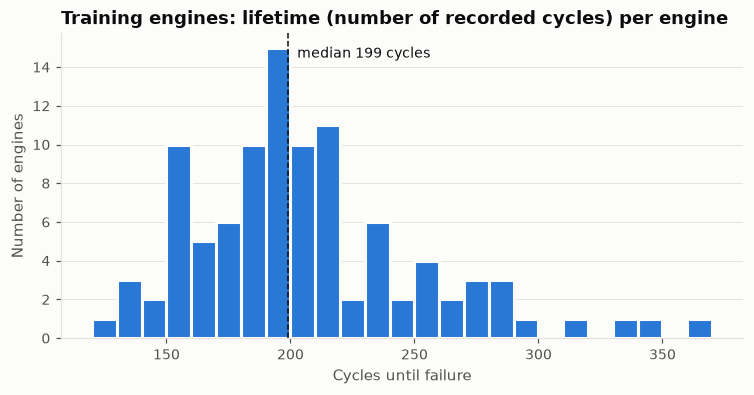

Lifetime IQR outliers (> 308 cycles): {67: 313, 69: 362, 92: 341, 96: 336}


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(train_life, bins=np.arange(120, 380, 10), color=SERIES[0], edgecolor=SURFACE, linewidth=2)
ax.axvline(train_life.median(), color=INK, linewidth=1, linestyle="--")
ax.annotate(f"median {train_life.median():.0f} cycles", xy=(train_life.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9)
ax.set(title="Training engines: lifetime (number of recorded cycles) per engine",
       xlabel="Cycles until failure", ylabel="Number of engines")
ax.grid(axis="x", visible=False)
save_figure(fig, "03_engine_lifetimes")
plt.show()

life_q1, life_q3 = train_life.quantile([0.25, 0.75])
long_lived = train_life[train_life > life_q3 + 1.5 * (life_q3 - life_q1)]
print(f"Lifetime IQR outliers (> {life_q3 + 1.5 * (life_q3 - life_q1):.0f} cycles):", long_lived.to_dict())

**What does this tell us?** Lifetimes are right-skewed. Most engines fail between about 150 and 250 cycles, and a tail of four engines (67, 69, 92, 96) lasts 313–362 cycles. These are long-lived engines rather than errors: the paper states that each engine starts with a random amount of initial wear and degrades at a randomly chosen rate. They stay in the data. Removing them would teach a future model that engines never last beyond about 290 cycles.

The skew also has a consequence for later sections: the longest engine contributes 362 rows and the shortest only 128. Fleet-level statistics computed per row therefore give long-lived engines about three times the weight of short-lived ones, which we keep in mind when interpreting correlations.

In [17]:
quality_report = pd.concat(
    [quality_checks.add_prefix("rows_"),
     variance_table[["n_unique", "top_value_pct", "constant", "near_zero_variance"]]],
    keys=["structural_checks", "variance_profile"],
)
quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv")

### 3.4 Audit summary and decisions

| Check | Finding | Why it matters | Treatment | Why this treatment |
|---|---|---|---|---|
| Missing values | None in train or test | Would bias statistics and break transforms | **None.** No imputation performed | Nothing to impute; adding an imputer would be dead code |
| Duplicate rows / `(unit_id, cycle)` keys | None | Duplicates inflate an engine's weight and break time order | **None** | Nothing to remove |
| Cycle continuity and ordering | All engines start at 1, no gaps, rows already sorted | Rolling and lag features assume consecutive, ordered cycles | **None.** We still sort explicitly before every time-based operation | Guards against reordering in any future data |
| Infinite / non-numeric / non-positive values | None | Would indicate corruption or parse errors | **None** | Data is valid |
| **Constant columns** | `op_setting_3`, `T2`, `P2`, `epr`, `farB`, `Nf_dmd`, `PCNfR_dmd` | No information, and scaling would divide by a zero standard deviation | **Drop** | One value in both train and test: they cannot distinguish a healthy engine from a failing one |
| **Near-zero variance** | `P15` (two values, 98 / 2%) | Very little usable information | **Keep for now, decide in Section 9** | It shows a real but heavily quantised link to wear (Section 3.2) |
| Lifetime spread | 128–362 cycles; 4 long-lived engines | Long engines dominate row-level statistics | **Keep all engines** | Real variation in initial wear and degradation rate, not errors |

The constant-column decision is based on the training data only. The same list is then applied to the test data.

In [18]:
def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop(columns=CONSTANT_COLUMNS)


train_clean = drop_constant_columns(train_raw)
test_clean = drop_constant_columns(test_raw)

ACTIVE_SETTINGS = [c for c in SETTING_COLUMNS if c not in CONSTANT_COLUMNS]
ACTIVE_SENSORS = [c for c in SENSOR_COLUMNS if c not in CONSTANT_COLUMNS]
print(f"train: {train_raw.shape} -> {train_clean.shape}")
print(f"{len(ACTIVE_SENSORS)} sensors retained:", ACTIVE_SENSORS)
print(f"{len(ACTIVE_SETTINGS)} operating settings retained:", ACTIVE_SETTINGS)

train: (20631, 26) -> (20631, 19)
15 sensors retained: ['T24', 'T30', 'T50', 'P15', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'htBleed', 'W31', 'W32']
2 operating settings retained: ['op_setting_1', 'op_setting_2']


## 4. Outlier analysis

**What / why.** In industrial sensor data, an "outlier" can mean two very different things:

- **A. A data-quality anomaly**: a reading that could not have happened physically, a transmission glitch, or an isolated spike that the engine's own neighbouring cycles contradict. These should be corrected or removed.
- **B. A legitimate extreme**: a real reading at the edge of the distribution. For an engine approaching failure, this is the degradation we are trying to detect. Removing it would remove the signal.

A standard statistical rule such as IQR cannot tell A from B. So we use IQR to *find* extreme values, and then look at **when** they occur, **in which direction**, and whether they are **isolated or sustained**.

`P15` is left out of the IQR analysis: with only two values its IQR is zero, so every 21.60 reading would be "flagged" (that behaviour was explained in Section 3.2).

In [19]:
IQR_MULTIPLIER = 1.5
OUTLIER_SENSORS = [s for s in ACTIVE_SENSORS if s not in NZV_COLUMNS]


def iqr_flags(df: pd.DataFrame, columns: list[str], k: float = IQR_MULTIPLIER):
    q1, q3 = df[columns].quantile(0.25), df[columns].quantile(0.75)
    lower, upper = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    return df[columns] < lower, df[columns] > upper, lower, upper


low_flags, high_flags, lower_fence, upper_fence = iqr_flags(train_clean, OUTLIER_SENSORS)
any_flag = low_flags | high_flags

iqr_summary = pd.DataFrame({
    "low": low_flags.sum(),
    "high": high_flags.sum(),
    "total": any_flag.sum(),
    "% of rows": 100 * any_flag.mean(),
    "engines affected": [train_clean.loc[any_flag[c], "unit_id"].nunique() for c in OUTLIER_SENSORS],
})
rows_flagged = any_flag.any(axis=1)
print(f"Rows with at least one IQR flag: {rows_flagged.sum():,} of {len(train_clean):,} ({100 * rows_flagged.mean():.1f}%)")
iqr_summary.sort_values("total", ascending=False)

Rows with at least one IQR flag: 2,431 of 20,631 (11.8%)


,low,high,total,% of rows,engines affected
Nc,23,1663,1686,8.1722,50
NRc,60,1483,1543,7.4790,51
Nf,4,316,320,1.5511,59
Ps30,0,167,167,0.8095,80
T30,19,146,165,0.7998,76
NRf,2,159,161,0.7804,44
phi,146,0,146,0.7077,59
W32,127,9,136,0.6592,70
T24,11,117,128,0.6204,73
T50,1,119,120,0.5816,72


**Result.** **11.8%** of training rows (2,431) have at least one sensor outside the 1.5 × IQR fences, and every one of the 100 engines is affected. Deleting these rows would remove about one row in eight, and it would remove them selectively, as the next checks show.

Note that the flags are almost all **one-sided** for each sensor: `T24`, `T30`, `T50`, `Ps30`, `BPR`, `htBleed`, `Nf`/`NRf` and `Nc`/`NRc` are flagged on the *high* side, while `P30`, `phi`, `W31` and `W32` are flagged on the *low* side. Random noise or glitches would produce flags on both sides.

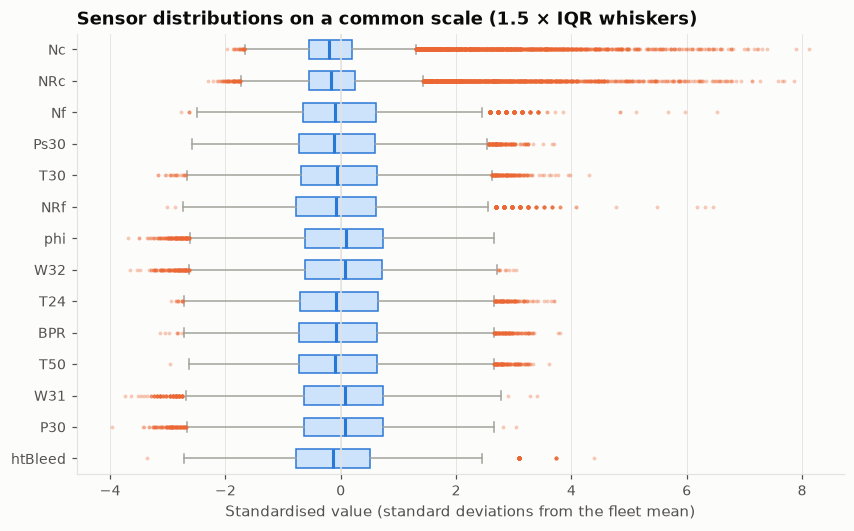

In [20]:
standardised = (train_clean[OUTLIER_SENSORS] - train_clean[OUTLIER_SENSORS].mean()) / train_clean[OUTLIER_SENSORS].std()
order = iqr_summary["total"].sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.boxplot(
    [standardised[c] for c in order], orientation="horizontal", tick_labels=order, widths=0.6,
    patch_artist=True, whis=IQR_MULTIPLIER,
    boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0], linewidth=1),
    medianprops=dict(color=SERIES[0], linewidth=2),
    whiskerprops=dict(color=NEUTRAL), capprops=dict(color=NEUTRAL),
    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=SERIES[1], markeredgewidth=0, alpha=0.35),
)
ax.axvline(0, color=GRID, linewidth=1)
ax.set(title="Sensor distributions on a common scale (1.5 × IQR whiskers)",
       xlabel="Standardised value (standard deviations from the fleet mean)", ylabel="")
ax.grid(axis="y", visible=False)
save_figure(fig, "04_sensor_boxplots")
plt.show()

**What does this tell us?** The flagged points (orange) form **long one-sided tails**, not scattered points on both sides. They are most pronounced for the core speeds `Nc` and `NRc`, which reach about 8 standard deviations above the mean, and their flags come from only about half the engines (50–51 of 100). In some engines the core speed climbs strongly near failure, while in others it barely moves. We look at this engine-to-engine difference in the EDA. The pattern points to values that drift steadily in one direction, rather than random measurement errors. The next check tests that directly.

### 4.1 When in an engine's life do the extremes occur?

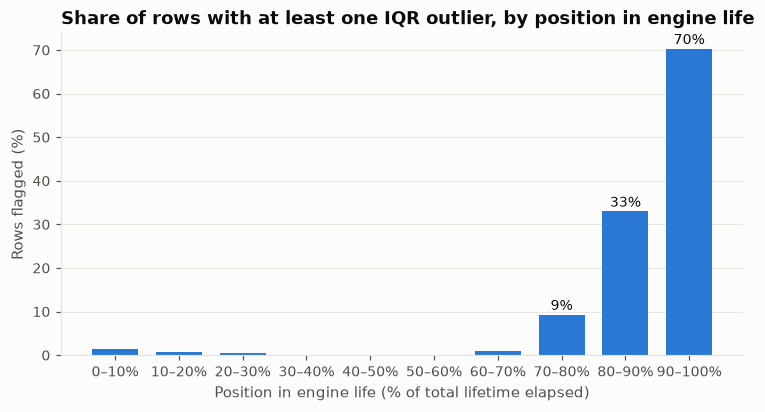

Share of all flagged rows that fall in the final 10% of life: 60.9%


In [21]:
flag_rate_by_life = (rows_flagged.groupby(life_bin, observed=True).mean() * 100)
share_in_final_decile = rows_flagged[life_bin == life_bin.cat.categories[-1]].sum() / rows_flagged.sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(flag_rate_by_life.index.astype(str), flag_rate_by_life.values, color=SERIES[0], width=0.72)
for bar, value in list(zip(bars, flag_rate_by_life.values))[-3:]:
    ax.annotate(f"{value:.0f}%", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set(title="Share of rows with at least one IQR outlier, by position in engine life",
       xlabel="Position in engine life (% of total lifetime elapsed)", ylabel="Rows flagged (%)")
ax.grid(axis="x", visible=False)
save_figure(fig, "04_outlier_rate_by_life_stage")
plt.show()
print(f"Share of all flagged rows that fall in the final 10% of life: {100 * share_in_final_decile:.1f}%")

**What does this tell us?** This is the key result of the outlier analysis.

- Through the first 70% of life, IQR outliers are almost absent (≤ 1.4% of rows per bin). The rate then rises steeply: 9% → 33% → 70%.
- In the final 10% of life, **70% of rows** are flagged. That bin alone contains **61% of all flagged rows**.

Measurement errors would not know how close the engine is to failure. These "outliers" are concentrated where degradation is strongest, so they are **type B: legitimate degradation values**.

The small bump in the first bin (1.4%) is also explainable: engines start with different amounts of initial wear, so a few begin their life near the edge of the fleet distribution.

**Direction check.** If the extremes are degradation, each sensor's flags should point the same way as its overall trend with age.

In [22]:
trend_with_age = train_clean[OUTLIER_SENSORS].corrwith(train_clean["cycle"] / train_clean.groupby("unit_id")["cycle"].transform("max"), method="spearman")
direction_check = pd.DataFrame({
    "trend with life (Spearman ρ)": trend_with_age,
    "dominant flag side": np.where(iqr_summary["high"] >= iqr_summary["low"], "high", "low"),
    "% flags on dominant side": 100 * iqr_summary[["high", "low"]].max(axis=1) / iqr_summary["total"],
})
direction_check["consistent"] = (
    (direction_check["trend with life (Spearman ρ)"] > 0) == (direction_check["dominant flag side"] == "high")
)
direction_check.sort_values("trend with life (Spearman ρ)")

,trend with life (Spearman ρ),dominant flag side,% flags on dominant side,consistent
phi,-0.6838,low,100.0000,True
P30,-0.6679,low,98.1818,True
W32,-0.6521,low,93.3824,True
W31,-0.6500,low,97.4359,True
NRc,0.2489,high,96.1115,True
Nc,0.3689,high,98.6358,True
Nf,0.5502,high,98.7500,True
NRf,0.5515,high,98.7578,True
T30,0.6031,high,88.4848,True
T24,0.6190,high,91.4062,True


**Result.** For all 14 sensors, the dominant flag side matches the direction of the sensor's trend over life. Sensors that rise with wear (temperatures, `Ps30`, `BPR`, `htBleed`, speeds) are flagged high, and sensors that fall (`P30`, `phi`, `W31`, `W32`) are flagged low. For 13 of the 14 sensors more than 90% of flags fall on the dominant side (the exception is `T30`, at 88%). This physically consistent pattern is what HPC degradation looks like; it is not noise.

### 4.2 Time-series inspection of one engine

To see the extremes in context, we plot four sensors for a representative engine (the one whose lifetime is closest to the fleet median), with the fleet-wide IQR fences and flagged cycles marked.

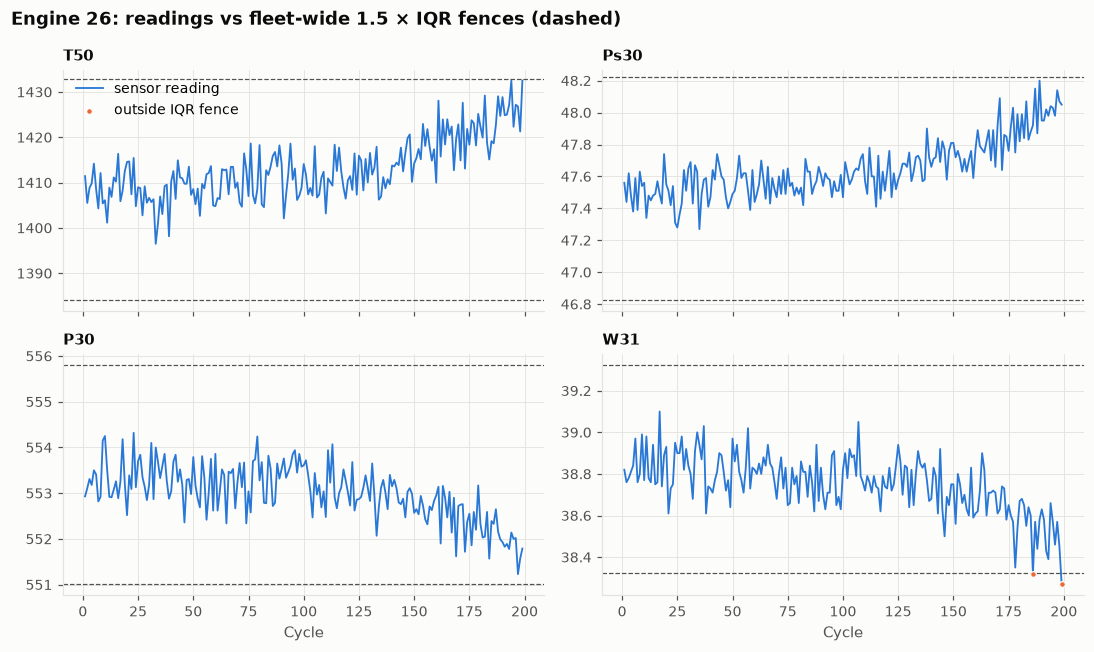

In [23]:
def plot_engine_with_fences(df, unit, sensors, lower, upper, flags):
    engine = df[df["unit_id"] == unit]
    fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
    for ax, sensor in zip(axes.flat, sensors):
        flagged = engine[flags.loc[engine.index, sensor]]
        ax.plot(engine["cycle"], engine[sensor], color=SERIES[0], linewidth=1.2, label="sensor reading")
        ax.scatter(flagged["cycle"], flagged[sensor], color=SERIES[1], s=14, zorder=3,
                   edgecolor=SURFACE, linewidth=0.8, label="outside IQR fence")
        for fence in (lower[sensor], upper[sensor]):
            ax.axhline(fence, color=INK_MUTED, linewidth=0.8, linestyle="--")
        ax.set_title(sensor, fontsize=10)
    for ax in axes[1]:
        ax.set_xlabel("Cycle")
    axes[0, 0].legend(loc="upper left")
    fig.suptitle(f"Engine {unit}: readings vs fleet-wide 1.5 × IQR fences (dashed)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
    fig.tight_layout()
    return fig


median_engine = (train_life - train_life.median()).abs().idxmin()
fig = plot_engine_with_fences(train_clean, median_engine, ["T50", "Ps30", "P30", "W31"], lower_fence, upper_fence, any_flag)
save_figure(fig, "04_engine_timeseries_fences")
plt.show()

**What does this tell us?** For this typical engine, each signal is noisy from cycle to cycle (±5 °R on `T50`, for example) but drifts steadily in its wear direction from roughly cycle 120 onwards. Only two readings actually cross a fence (`W31`, at the very end of life), and both lie *on* the downward trend rather than jumping away from it. A data error would be a single point that the cycles around it contradict.

Two practical lessons follow:
1. **The fleet-wide fences are not a meaningful boundary for one engine.** This engine degrades clearly while staying inside them, and engines with higher initial wear cross them earlier. Being "outside the fence" depends on the fleet distribution, not on the engine's condition.
2. **Clipping at the fences would flatten the end of the trajectory**, exactly where a RUL model needs the most resolution.

### 4.3 Screening for genuine data-quality anomalies (type A)

Ruling out type A requires its own test. A glitch is a reading that disagrees with the engine's **own neighbouring cycles**. We compare every reading with a centred rolling median of that engine's readings (11 cycles), and flag it if the deviation exceeds 6 robust standard deviations (a scaled MAD — median absolute deviation — of all deviations for that sensor).

The centred window uses future cycles. That is acceptable here because this is an **offline quality check on the data**, not a feature. No model input is built this way (see Section 8).

In [24]:
SPIKE_WINDOW = 11
SPIKE_THRESHOLD = 6.0
MAD_TO_STD = 1.4826


def isolated_spikes(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    lifetime = df.groupby("unit_id")["cycle"].transform("max")
    found = []
    for sensor in sensors:
        local_median = df.groupby("unit_id")[sensor].transform(
            lambda s: s.rolling(SPIKE_WINDOW, center=True, min_periods=SPIKE_WINDOW // 2).median()
        )
        residual = df[sensor] - local_median
        robust_sd = MAD_TO_STD * (residual - residual.median()).abs().median()
        hits = residual.abs() > SPIKE_THRESHOLD * robust_sd
        found.append(pd.DataFrame({
            "sensor": sensor,
            "unit_id": df.loc[hits, "unit_id"],
            "cycle": df.loc[hits, "cycle"],
            "cycles_before_failure": (lifetime - df["cycle"])[hits],
            "value": df.loc[hits, sensor],
            "deviation (robust SD)": (residual / robust_sd)[hits].round(1),
        }))
    return pd.concat(found, ignore_index=True)


spikes = isolated_spikes(train_clean, OUTLIER_SENSORS)
spikes.sort_values(["cycles_before_failure", "unit_id"])

,sensor,unit_id,cycle,cycles_before_failure,value,deviation (robust SD)
1,Nf,9,201,0,"2,388.5000",11.8000
7,Nc,9,201,0,"9,239.7600",6.1000
10,NRf,9,201,0,"2,388.5600",15.0000
15,NRc,9,201,0,"8,289.6300",6.3000
2,Nf,18,195,0,"2,388.4400",10.3000
11,NRf,18,195,0,"2,388.3900",8.4000
3,Nf,48,231,0,"2,388.5200",13.0000
12,NRf,48,231,0,"2,388.5500",14.5000
16,NRc,48,231,0,"8,290.2500",6.5000
6,Nf,51,213,0,"2,388.5600",11.1000


In [25]:
# The one candidate that is not at end of life: compare it with that engine's normal range for the sensor.
early = spikes[spikes["cycles_before_failure"] > 10]
for row in early.itertuples():
    engine_values = train_clean.loc[train_clean["unit_id"] == row.unit_id, row.sensor]
    print(f"Engine {row.unit_id}, {row.sensor} at cycle {row.cycle}: value {row.value} | "
          f"engine range {engine_values.min()}–{engine_values.max()} | "
          f"fleet IQR fences {lower_fence[row.sensor]:.3f}–{upper_fence[row.sensor]:.3f}")

Engine 100, W32 at cycle 6: value 23.5751 | engine range 22.9333–23.5751 | fleet IQR fences 23.004–23.584


**Result.** Across roughly 290,000 sensor readings (20,631 rows × 14 sensors), the screen finds **18 candidate spikes**:

- **17 occur in the final 0–2 cycles of an engine's life** (engines 9, 18, 48 and 51), in the speed sensors `Nf`, `NRf`, `Nc` and `NRc`. They are not glitches. At failure the speeds accelerate sharply, and a centred median cannot follow a curve that turns that quickly. These are the most extreme degradation values in the dataset.
- **1 occurs early in life**: `W32` on engine 100 at cycle 6, right at the threshold (6.0 robust SD). It is that engine's highest `W32` reading, but it still lies inside the fleet IQR fences, and it is *high*, i.e. in the healthy direction for a sensor that falls with wear. It is a large noise draw, not an impossible reading.

**No reading is physically impossible, and no reading is contradicted both by its neighbours and by the physics.** We found **no type-A anomalies**.

### 4.4 Outlier decision

| Candidate | Classification | Decision |
|---|---|---|
| 2,431 rows outside 1.5 × IQR fences | **B. Degradation.** 61% fall in the final 10% of life, and every sensor's flags match its wear direction | **Keep, unmodified** |
| 17 sharp changes in the final 0–2 cycles | **B. End-of-life acceleration** | **Keep** |
| 1 early `W32` reading at the detection threshold | Noise within the engine's normal range | **Keep** |
| 4 long-lived engines (313–362 cycles) | Natural variation in initial wear and degradation rate | **Keep** |

**No rows were removed, clipped or winsorised.** The data shows no defensible reason to remove anything, and removal would systematically delete late-life data, which is exactly where a RUL model most needs to be accurate.

Two consequences are carried forward:

1. **Noise is a bigger problem than outliers.** Section 4.2 shows strong cycle-to-cycle noise around slow trends. That is the motivation for smoothing features (rolling and exponentially weighted statistics) in Section 8, which handle noise without deleting data.
2. **Scaling must respect the tails.** Because the extremes are real signal, we keep them unmodified. The choice of scaler is made in Section 11 with this in mind.

## 5. Target engineering: Remaining Useful Life (RUL)

**What.** The raw files contain no target column. We derive it from how each split was recorded.

**Training engines** run until they fail, so an engine's last recorded cycle is its failure point:

$$\text{RUL}_{\text{train}}(t) = \text{last cycle of the engine} - t$$

**Test engines** stop *before* failure. `RUL_FD001.txt` gives, for test engine *i* (line *i*), the number of cycles it would still have run after its last observed cycle. The failure cycle is therefore `last observed cycle + true RUL`, and:

$$\text{RUL}_{\text{test}}(t) = (\text{last observed cycle} + \text{true RUL}) - t$$

**Assumption.** RUL = 0 at the last recorded training cycle, i.e. the engine fails immediately after that cycle. This follows the readme ("the fault grows in magnitude until system failure").

### Why this creates a leakage risk

RUL is computed from the **final** cycle, which is only known once the engine has failed. The target is allowed to use that information. Features are not. Anything derived from an engine's total lifetime — its length, `cycle / lifetime`, the `life_fraction` used for analysis in Sections 3–4 — would give the answer away. A model trained on such features would score well offline and fail in service, where the lifetime is exactly what we do not know.

Guard rails used from here on:

1. The target has its own name, `RUL`, and is excluded from every feature list.
2. No helper column that encodes the lifetime (e.g. `max_cycle`) is ever stored in a dataframe.
3. An assertion (`assert_no_target_leakage`) checks every candidate feature list. Section 12 runs a full audit.
4. The test labels are used only to check that the test RUL is built correctly. **No EDA decision is based on the test set.**

In [26]:
TARGET = "RUL"
LEAKY_COLUMN_NAMES = {TARGET, "max_cycle", "lifetime", "life_fraction", "cycles_before_failure"}


def add_train_rul(df: pd.DataFrame) -> pd.DataFrame:
    final_cycle = df.groupby("unit_id")["cycle"].transform("max")
    return df.assign(**{TARGET: (final_cycle - df["cycle"]).astype("int32")})


def add_test_rul(df: pd.DataFrame, true_rul: pd.DataFrame) -> pd.DataFrame:
    if set(df["unit_id"]) != set(true_rul["unit_id"]):
        raise ValueError("RUL file does not cover exactly the test engines")
    last_observed = df.groupby("unit_id")["cycle"].transform("max")
    rul_after_last = df["unit_id"].map(true_rul.set_index("unit_id")["true_rul"])
    return df.assign(**{TARGET: (last_observed + rul_after_last - df["cycle"]).astype("int32")})


def assert_no_target_leakage(feature_columns: list[str]) -> None:
    leaked = LEAKY_COLUMN_NAMES.intersection(feature_columns)
    assert not leaked, f"target-derived columns in feature list: {leaked}"


train_df = add_train_rul(train_clean)
test_df = add_test_rul(test_clean, test_true_rul)

CANDIDATE_FEATURES = ["cycle"] + ACTIVE_SETTINGS + ACTIVE_SENSORS
assert_no_target_leakage(CANDIDATE_FEATURES)
assert set(train_df.columns) == set(train_clean.columns) | {TARGET}, "unexpected helper column stored"
print(f"{len(CANDIDATE_FEATURES)} candidate input columns (target excluded):", CANDIDATE_FEATURES)

18 candidate input columns (target excluded): ['cycle', 'op_setting_1', 'op_setting_2', 'T24', 'T30', 'T50', 'P15', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'htBleed', 'W31', 'W32']


### 5.1 Validating the target

In [27]:
def validate_rul(df: pd.DataFrame, final_rul: pd.Series | None = None) -> pd.Series:
    # final_rul: expected RUL at each engine's last row (0 for run-to-failure data).
    by_engine = df.groupby("unit_id")
    last_rows = by_engine.tail(1).set_index("unit_id")[TARGET]
    expected_last = pd.Series(0, index=last_rows.index) if final_rul is None else final_rul
    steps = by_engine[TARGET].diff().dropna()
    return pd.Series({
        "RUL at final row matches expectation": bool(last_rows.sort_index().equals(expected_last.sort_index().astype(last_rows.dtype))),
        "all RUL values non-negative": bool((df[TARGET] >= 0).all()),
        "RUL falls by exactly 1 per cycle": bool(steps.eq(-1).all()),
        "RUL + cycle constant within each engine": bool(by_engine.apply(lambda g: (g[TARGET] + g["cycle"]).nunique() == 1).all()),
    })


rul_validation = pd.DataFrame({
    "train": validate_rul(train_df),
    "test": validate_rul(test_df, final_rul=test_true_rul.set_index("unit_id")["true_rul"]),
})
assert rul_validation.all().all(), "RUL validation failed"
rul_validation

,train,test
RUL at final row matches expectation,True,True
all RUL values non-negative,True,True
RUL falls by exactly 1 per cycle,True,True
RUL + cycle constant within each engine,True,True


In [28]:
# First and last three cycles of three engines (train) and the same for one test engine.
example_engines = [1, 50, 100]
examples = pd.concat(
    [train_df[train_df["unit_id"] == u].iloc[np.r_[0:3, -3:0]] for u in example_engines]
)[["unit_id", "cycle", TARGET]]
test_example = test_df[test_df["unit_id"] == 1].iloc[np.r_[0:3, -3:0]][["unit_id", "cycle", TARGET]]
print("Training engines:")
display(examples.set_index(["unit_id", "cycle"]).T)
print(f"Test engine 1 (true RUL after last cycle in RUL_{SUBSET}.txt = {test_true_rul.loc[0, 'true_rul']}):")
display(test_example.set_index(["unit_id", "cycle"]).T)

Training engines:


unit_id  1                          50                         100                      
cycle    1    2    3   190 191 192  1    2    3   196 197 198  1    2    3   198 199 200
RUL      191  190  189   2   1   0  197  196  195   2   1   0  199  198  197   2   1   0

Test engine 1 (true RUL after last cycle in RUL_FD001.txt = 112):


unit_id    1                         
cycle     1    2    3    29   30   31
RUL      142  141  140  114  113  112

**Result.** All four checks pass in both splits:

- every training engine ends at RUL = 0, and every test engine ends at exactly the value given in `RUL_FD001.txt`;
- RUL is never negative, and it decreases by exactly one per cycle;
- `RUL + cycle` is constant within each engine (it equals the failure cycle).

The examples show this directly. Engine 1 fails after cycle 192, so its RUL runs 191 → 0. Test engine 1 is observed for 31 cycles and still has 112 cycles left at its last observation, so its RUL there is 112 rather than 0.

### 5.2 Distribution of the training target

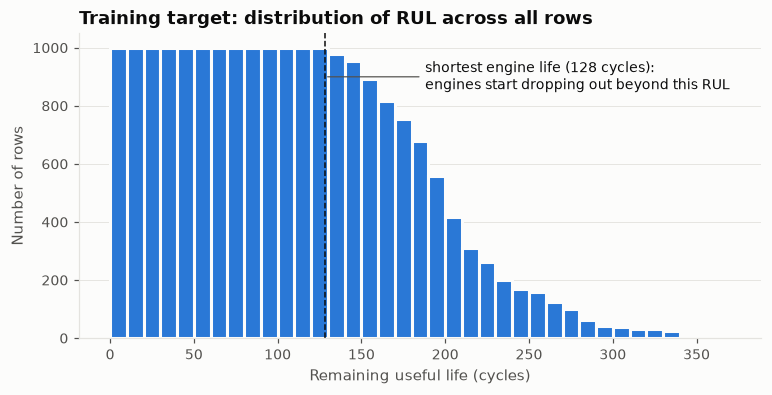

,count,mean,std,min,25%,50%,75%,max
RUL,"20,631.0000",107.8079,68.8810,0.0000,51.0000,103.0000,155.0000,361.0000


In [29]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(train_df[TARGET], bins=np.arange(0, train_df[TARGET].max() + 11, 10), color=SERIES[0],
        edgecolor=SURFACE, linewidth=2)
ax.axvline(train_life.min(), color=INK, linewidth=1, linestyle="--")
ax.annotate(f"shortest engine life ({train_life.min()} cycles):\nengines start dropping out beyond this RUL",
            xy=(train_life.min(), 900), xytext=(train_life.min() + 60, 900), fontsize=9, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=INK_MUTED, linewidth=0.8))
ax.set(title="Training target: distribution of RUL across all rows",
       xlabel="Remaining useful life (cycles)", ylabel="Number of rows")
ax.grid(axis="x", visible=False)
save_figure(fig, "05_rul_distribution")
plt.show()
train_df[TARGET].describe().to_frame().T

**What does this tell us?** The shape follows directly from how RUL is built. Every engine contributes exactly one row at each RUL from its lifetime − 1 down to 0. The number of rows with RUL = *r* is therefore simply **the number of engines that lived longer than *r* cycles**: the histogram is a survival curve.

- Up to RUL 127 all 100 engines contribute, so the distribution is flat (1,000 rows per 10-cycle bin).
- Beyond the shortest lifetime (128 cycles) engines drop out one by one, and the tail up to RUL 361 is made up of fewer and fewer long-lived engines.

**Consequences:**

1. Rows with high RUL come from a **small, unrepresentative subset** of long-lived engines. Any relationship learned there rests on few engines.
2. Early-life rows mostly describe a healthy engine. Whether the sensors can tell RUL 300 apart from RUL 200 is an empirical question, answered in Section 6.5. It decides whether the target should be capped.

## 6. Exploratory data analysis

**Questions this section answers:**

1. What do the sensor distributions look like?
2. Which sensors change as an engine degrades, in which direction, and how consistently across engines?
3. When does degradation become visible?
4. How noisy is each sensor relative to its degradation signal?
5. Which sensors repeat each other?
6. Which sensors carry little useful information?

All statistics are computed on the **training engines only**. Several charts align engines by **RUL** (cycles before failure) instead of by cycle number. That is legitimate for *analysis*, because it shows what failure looks like. It is not a feature.

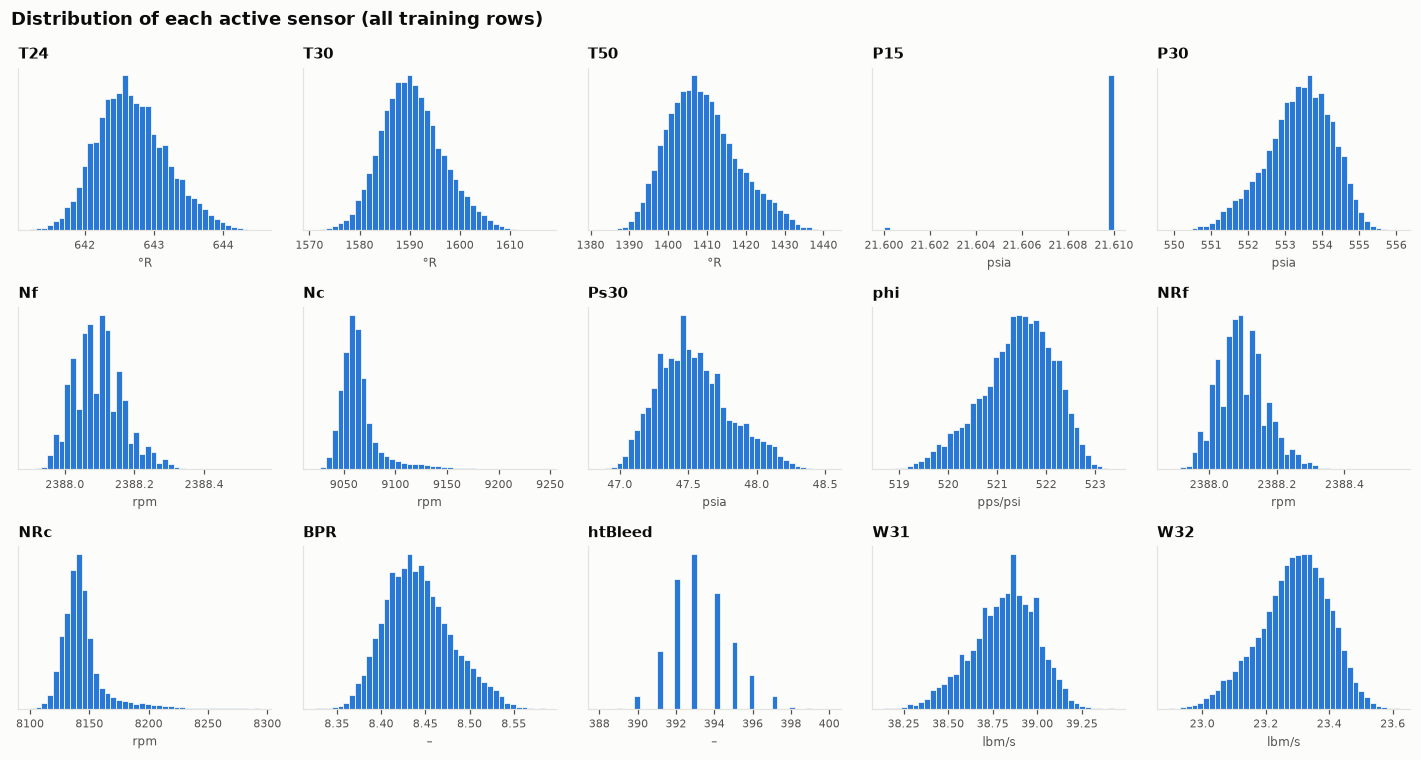

,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,NRc,BPR,htBleed,W31,W32
skewness,0.3200,0.3100,0.4400,-6.9200,-0.3900,0.4800,2.5600,0.4700,-0.4400,0.4700,2.3700,0.3900,0.3500,-0.3600,-0.3500


In [30]:
SENSOR_UNITS = {symbol: units for symbol, _, units in SENSOR_METADATA}
SENSOR_DESCRIPTIONS = {symbol: description for symbol, description, _ in SENSOR_METADATA}

fig, axes = plt.subplots(3, 5, figsize=(13, 7))
for ax, sensor in zip(axes.flat, ACTIVE_SENSORS):
    ax.hist(train_df[sensor], bins=40, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(sensor, fontsize=10)
    ax.set_xlabel(SENSOR_UNITS[sensor], fontsize=8)
    ax.tick_params(labelsize=7)
    ax.ticklabel_format(axis="x", useOffset=False, style="plain")
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Distribution of each active sensor (all training rows)", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "06_sensor_distributions")
plt.show()

train_df[ACTIVE_SENSORS].skew().round(2).rename("skewness").to_frame().T

**What does this tell us?**

- Most sensors are **unimodal and mildly right- or left-skewed** (|skew| ≈ 0.3–0.5). The skew points in each sensor's degradation direction, because the late-life rows form one tail.
- `Nc` and `NRc` are **strongly right-skewed** (skew ≈ 2.4–2.6). A minority of rows sit far above the bulk, which matches the one-sided outliers seen in Section 4.
- `htBleed` is **integer-valued**, `Nf` and `NRf` have **coarse resolution** (visible as gaps between bars), and `P15` has **two values** (hence its extreme skew of −6.9). These are properties of the recorded resolution, not of the engine. They are one reason raw readings are noisy, and why smoothed features (Section 8) are worth testing.
- There is no bimodality, which is consistent with FD001 having a single operating condition. Section 7 checks this formally.

### 6.1 Degradation profiles: each sensor aligned by remaining life

To see degradation, we align all engines at failure (RUL = 0) and plot each sensor's fleet median and interquartile band against RUL. Each sensor is shown as standard deviations away from its **early-life baseline** (fleet mean and SD over the first 30 cycles of every engine), so all panels share one scale and "0" means "as healthy as a new engine".

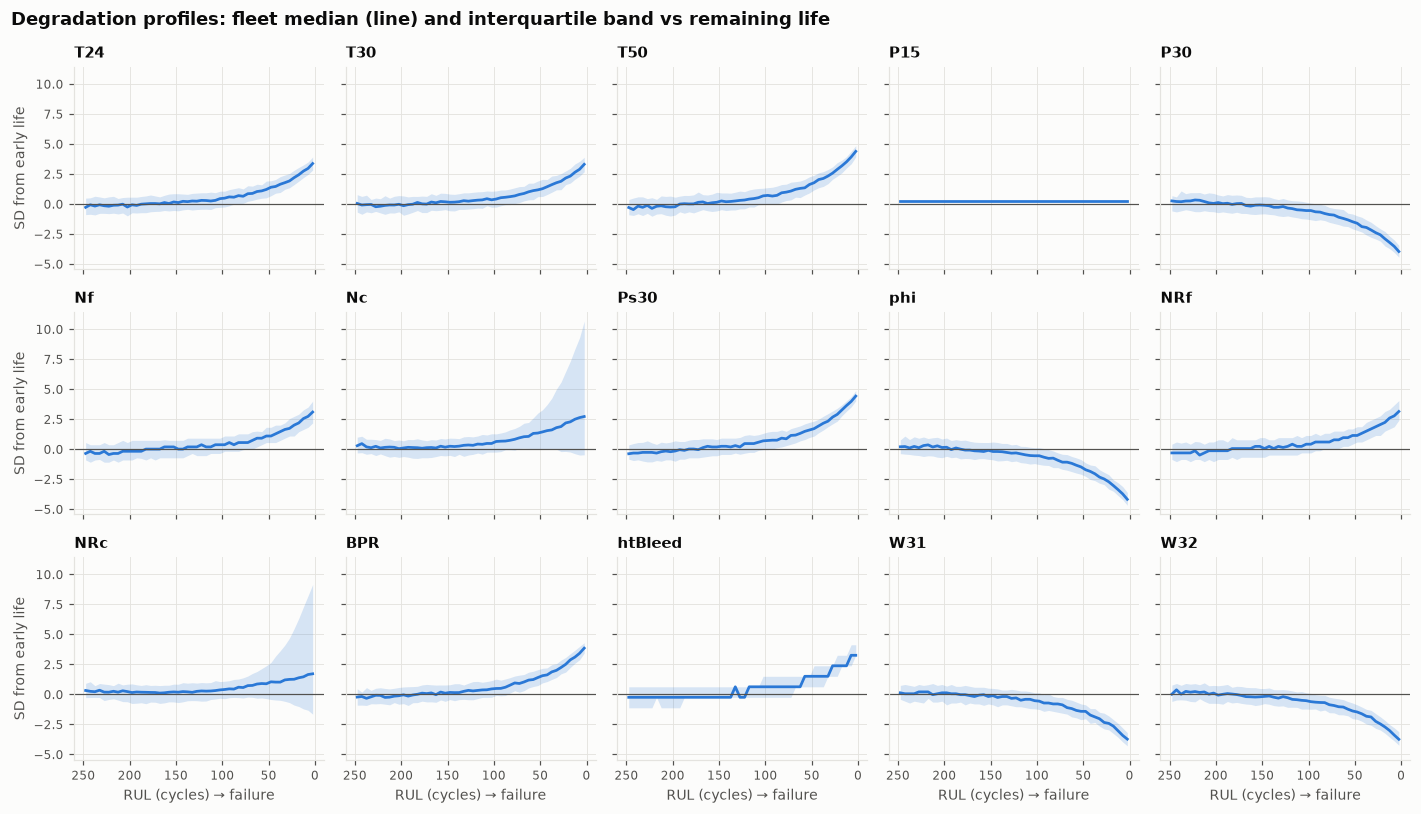

Engines contributing at RUL = 250: 17 of 100


In [31]:
EARLY_LIFE_CYCLES = 30
RUL_PLOT_MAX = 250
RUL_BIN_WIDTH = 5


def baseline_standardise(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    # Deviation from the fleet's early-life (healthy) state, in early-life standard deviations.
    early = df.loc[df["cycle"] <= EARLY_LIFE_CYCLES, sensors]
    return (df[sensors] - early.mean()) / early.std()


baseline_z = baseline_standardise(train_df, ACTIVE_SENSORS)
rul_bin = (train_df[TARGET] // RUL_BIN_WIDTH) * RUL_BIN_WIDTH + RUL_BIN_WIDTH / 2
in_range = train_df[TARGET] < RUL_PLOT_MAX
profile = baseline_z[in_range].groupby(rul_bin[in_range]).quantile([0.25, 0.5, 0.75]).unstack()

fig, axes = plt.subplots(3, 5, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, sensor in zip(axes.flat, ACTIVE_SENSORS):
    p = profile[sensor]
    ax.fill_between(p.index, p[0.25], p[0.75], color=SERIES[0], alpha=0.18, linewidth=0)
    ax.plot(p.index, p[0.5], color=SERIES[0], linewidth=1.8)
    ax.axhline(0, color=INK_MUTED, linewidth=0.8)
    ax.set_title(sensor, fontsize=10)
    ax.tick_params(labelsize=8)
axes[0, 0].invert_xaxis()
for ax in axes[-1]:
    ax.set_xlabel("RUL (cycles) → failure", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("SD from early life", fontsize=9)
fig.suptitle("Degradation profiles: fleet median (line) and interquartile band vs remaining life",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "06_degradation_profiles")
plt.show()
print(f"Engines contributing at RUL = {RUL_PLOT_MAX}: {(train_life > RUL_PLOT_MAX).sum()} of 100")

**What does this tell us?** This is the central EDA chart.

- **Twelve sensors show a clear, monotonic degradation signature.** `T24`, `T30`, `T50`, `Ps30`, `BPR`, `htBleed`, `Nf` and `NRf` rise towards failure; `P30`, `phi`, `W31` and `W32` fall. The physical picture is consistent: a degrading high-pressure compressor runs hotter (`T30`, `T50`), delivers less pressure (`P30`), and the controller compensates through fuel flow and speeds.
- **The signals are not linear in RUL.** Each curve stays near its baseline for a long stretch and then bends sharply in the last ~50–100 cycles. A sensor can therefore be strongly related to RUL without being *linearly* correlated with it (see 6.4).
- **`Nc` and `NRc` look different.** Their median rises late, but the interquartile band widens dramatically. Engines disagree with each other (6.2 shows why).
- **`P15` barely moves.** Its median stays at baseline, as expected for a two-valued sensor.
- On the right-hand side of each panel (RUL > ~150) the curves are close to flat. Only 17 engines live beyond 250 cycles, so the far left of each panel rests on few engines.

### 6.2 Multiple-engine comparison: is degradation consistent across engines?

The same two sensors for 12 randomly chosen engines, plotted against **cycle** (what an operator sees) and against **RUL** (aligned at failure). The thin lines use a centred 5-cycle moving average **for display only**, to make overlapping engines readable. No feature is computed this way.

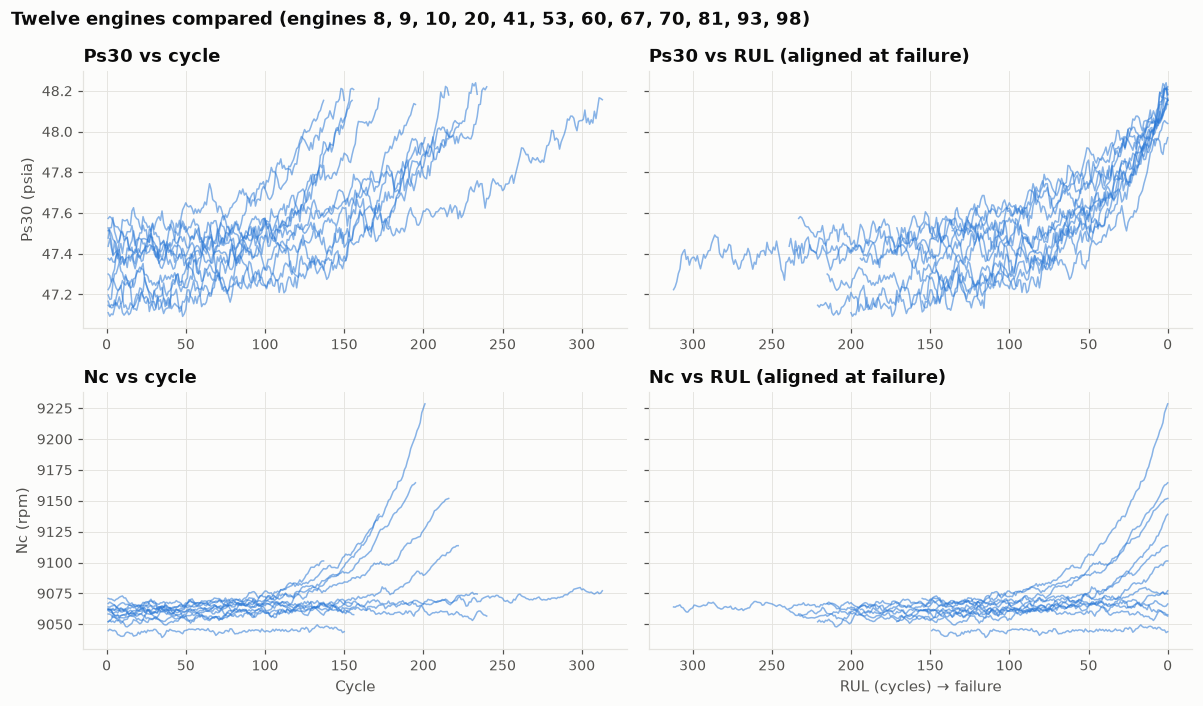

In [32]:
DISPLAY_SMOOTHING = 5
rng = np.random.default_rng(RANDOM_STATE)
sample_engines = np.sort(rng.choice(train_df["unit_id"].unique(), size=12, replace=False))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharey="row")
for row, sensor in enumerate(["Ps30", "Nc"]):
    for unit in sample_engines:
        engine = train_df[train_df["unit_id"] == unit]
        smooth = engine[sensor].rolling(DISPLAY_SMOOTHING, center=True, min_periods=1).mean()
        axes[row, 0].plot(engine["cycle"], smooth, color=SERIES[0], alpha=0.55, linewidth=1)
        axes[row, 1].plot(engine[TARGET], smooth, color=SERIES[0], alpha=0.55, linewidth=1)
    axes[row, 0].set_ylabel(f"{sensor} ({SENSOR_UNITS[sensor]})")
    axes[row, 1].invert_xaxis()
axes[0, 0].set_title("Ps30 vs cycle")
axes[0, 1].set_title("Ps30 vs RUL (aligned at failure)")
axes[1, 0].set_title("Nc vs cycle")
axes[1, 1].set_title("Nc vs RUL (aligned at failure)")
axes[1, 0].set_xlabel("Cycle")
axes[1, 1].set_xlabel("RUL (cycles) → failure")
fig.suptitle(f"Twelve engines compared (engines {', '.join(map(str, sample_engines))})",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "06_engine_comparison")
plt.show()

**What does this tell us?**

- **Aligned by cycle (left), engines look scattered:** they fail at different ages, so the upturns happen at different places. **Aligned by RUL (right), `Ps30` collapses onto one shared shape**: roughly flat, then rising steadily over the last ~100 cycles and steeply near the end. The degradation *pattern* is common to the fleet. Only its *timing* differs, which is exactly what a RUL model has to learn from the sensors.
- **Each engine starts at a different level.** Even at cycle 1 the `Ps30` lines differ, matching the paper's note on random initial wear and manufacturing variation. This suggests features that measure change *relative to the engine's own history* (Section 8).
- **`Nc` does not collapse to one shape.** Some engines' core speed climbs by 100+ rpm towards failure, while others stay almost flat. Across all 100 engines, 29 actually end *below* their early-life `Nc` (6.3). That explains its wide band in 6.1 and its one-sided outliers in Section 4. The size of its response, and even its direction, depends on the engine.

### 6.3 Trend consistency: does each sensor move the same way in every engine?

For each engine separately we compute the Spearman correlation between a sensor and the cycle number. A useful degradation sensor should have a strong correlation **with the same sign in every engine**.

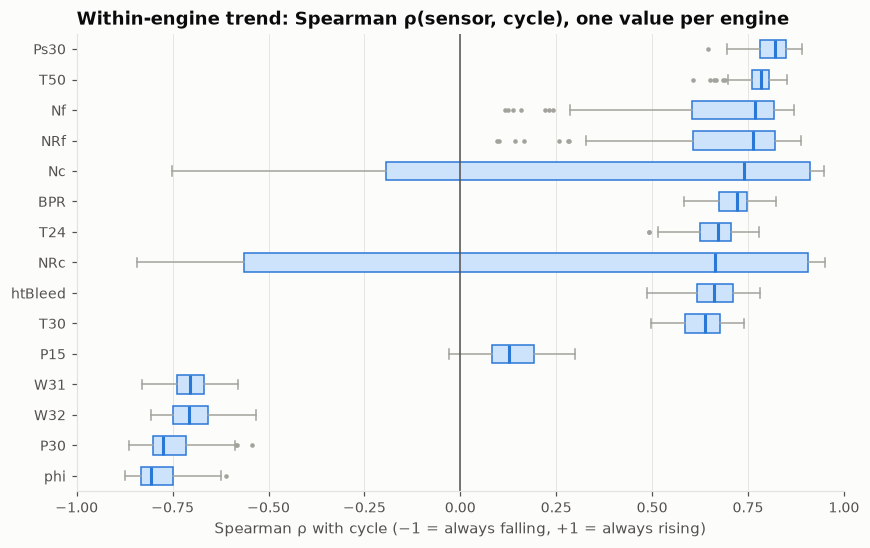

,median ρ,10th pct,90th pct,% engines with same sign as median
phi,-0.8075,-0.8434,-0.6910,100.0000
P30,-0.7742,-0.8175,-0.6483,100.0000
W32,-0.7080,-0.7754,-0.6234,100.0000
W31,-0.7059,-0.7811,-0.6231,100.0000
P15,0.1264,0.0521,0.2509,61.0000
T30,0.6368,0.5428,0.7082,100.0000
htBleed,0.6609,0.5827,0.7370,100.0000
NRc,0.6634,-0.7488,0.9340,60.0000
T24,0.6713,0.5883,0.7356,100.0000
BPR,0.7210,0.6275,0.7768,100.0000


In [33]:
def within_engine_trend(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    # Spearman ρ(sensor, cycle) per engine = Pearson correlation of within-engine ranks.
    ranks = df.groupby("unit_id")[sensors + ["cycle"]].rank()
    ranks["unit_id"] = df["unit_id"]
    with np.errstate(invalid="ignore", divide="ignore"):
        return ranks.groupby("unit_id").apply(lambda g: g[sensors].corrwith(g["cycle"]))


engine_trends = within_engine_trend(train_df, ACTIVE_SENSORS)
median_trend = engine_trends.median()
trend_summary = pd.DataFrame({
    "median ρ": median_trend,
    "10th pct": engine_trends.quantile(0.10),
    "90th pct": engine_trends.quantile(0.90),
    "% engines with same sign as median": 100 * np.sign(engine_trends).eq(np.sign(median_trend)).mean(),
}).sort_values("median ρ")

order = trend_summary.index.tolist()
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.boxplot([engine_trends[s].dropna() for s in order], orientation="horizontal", tick_labels=order,
           widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]), medianprops=dict(color=SERIES[0], linewidth=2),
           whiskerprops=dict(color=NEUTRAL), capprops=dict(color=NEUTRAL),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=NEUTRAL, markeredgewidth=0))
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set(title="Within-engine trend: Spearman ρ(sensor, cycle), one value per engine",
       xlabel="Spearman ρ with cycle (−1 = always falling, +1 = always rising)", xlim=(-1, 1))
ax.grid(axis="y", visible=False)
save_figure(fig, "06_within_engine_trend")
plt.show()
trend_summary

**What does this tell us?**

- **Twelve sensors have a consistent direction in 100% of engines**, with median |ρ| between 0.64 and 0.82. `Ps30` (0.82), `phi` (−0.81), `T50` (0.78), `P30` (−0.77) and `Nf`/`NRf` (≈0.77) are the most strongly monotonic. `Nf`/`NRf` have a long lower whisker: in a few engines their trend is weak.
- **`Nc` and `NRc` are inconsistent.** Their median trend is positive, but they *fall* over life in 29% and 40% of engines respectively. A sensor whose direction depends on the engine cannot be read the same way across the fleet, so its raw level is a weaker RUL indicator than its median suggests.
- **`P15` has almost no trend** (median ρ = 0.13). In **38 of 100 engines it never changes value at all**, so its trend is undefined there. Those engines are excluded from its box, and they are why only 61% of engines show the median's sign.

### 6.4 Relationship between each sensor and RUL (pooled over the fleet)

In [34]:
rul_relationship = pd.DataFrame({
    "Pearson r": train_df[ACTIVE_SENSORS + ["cycle"]].corrwith(train_df[TARGET]),
    "Spearman ρ": train_df[ACTIVE_SENSORS + ["cycle"]].corrwith(train_df[TARGET], method="spearman"),
})
rul_relationship["|ρ| − |r|"] = rul_relationship["Spearman ρ"].abs() - rul_relationship["Pearson r"].abs()
rul_relationship.sort_values("Spearman ρ", key=np.abs, ascending=False)

,Pearson r,Spearman ρ,|ρ| − |r|
cycle,-0.7362,-0.7868,0.0506
Ps30,-0.6962,-0.7181,0.0219
T50,-0.6789,-0.7018,0.0228
phi,0.6720,0.6931,0.0212
P30,0.6572,0.6788,0.0216
BPR,-0.6427,-0.6659,0.0232
W32,0.6357,0.6574,0.0218
W31,0.6294,0.6533,0.0239
htBleed,-0.6062,-0.6294,0.0232
T24,-0.6065,-0.6286,0.0221


**What does this tell us?**

- The strongest single sensors are **`Ps30` (ρ = −0.72), `T50` (−0.70), `phi` (+0.69), `P30` (+0.68), `BPR` (−0.67), `W32` and `W31` (≈ +0.65)**. Higher temperatures and static pressure mean less life left, and lower `P30`, `phi` and coolant bleeds mean less life left.
- **For all 12 consistently trending sensors, Spearman |ρ| exceeds Pearson |r|**, by a small but systematic 0.01–0.02. This matches the curvature seen in 6.1: the relationships are monotonic but not linear. Pooled over all rows the gap is small, because most rows sit in the long, flat early-life segment. Even so, a linear measure slightly understates these sensors, which is one reason Section 9 also uses mutual information.
- For `Nc` and `NRc` it is the other way round (Pearson > Spearman). Their Pearson value is pulled up by the few engines with very large late-life excursions. Rank correlation, which is not driven by those extreme rows, is weaker.
- **`Nc` (−0.32) and `NRc` (−0.20) are weak when pooled**, because engines disagree about their direction (6.3). **`P15` is weak (−0.13).**
- **`cycle` has the strongest pooled correlation of all (ρ = −0.79).** That is partly built in: RUL = lifetime − cycle, and lifetimes cluster around 200. `cycle` is a legitimate input (an operator knows an engine's age), but on its own it can only predict the *fleet-average* remaining life. It cannot distinguish a worn engine from a healthy one of the same age. Its real contribution is assessed in Section 9.
- These are **pooled** correlations. Long-lived engines contribute more rows (Section 3.3), and pooled correlation mixes differences between engines with changes within an engine. The within-engine view in 6.3 is the cleaner test of degradation behaviour.

### 6.5 When does degradation become visible?

To estimate this at fleet level, we combine the 12 sensors with a consistent direction (6.3). Each is standardised against early life (6.1), its sign is flipped so that "worse" is always positive, and the 12 are averaged. This composite is **for analysis only**. Whether something like it becomes a feature is decided in Section 8.

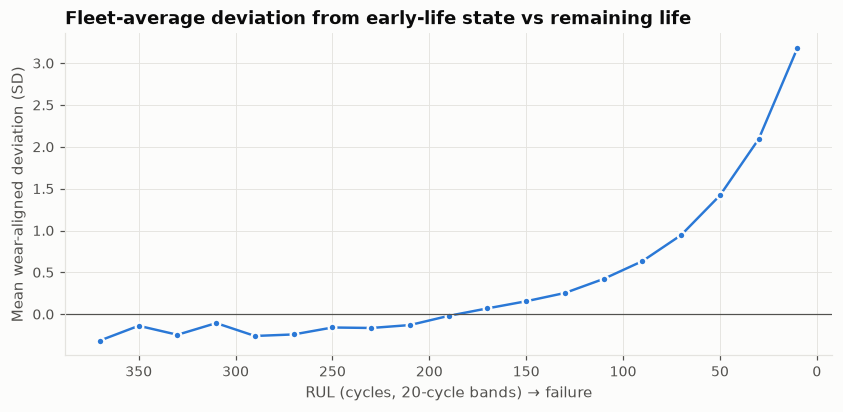

Sensors in the composite: ['phi', 'P30', 'W32', 'W31', 'T30', 'htBleed', 'T24', 'BPR', 'NRf', 'Nf', 'T50', 'Ps30']


RUL,"[0, 20)","[20, 40)","[40, 60)","[60, 80)","[80, 100)","[100, 120)","[120, 140)","[140, 160)","[160, 180)","[180, 200)","[200, 220)","[220, 240)","[240, 260)","[260, 280)","[280, 300)","[300, 320)","[320, 340)","[340, 360)","[360, 380)"
mean,3.1800,2.0900,1.4200,0.9500,0.6300,0.4200,0.2500,0.1500,0.0700,-0.0200,-0.1300,-0.1600,-0.1600,-0.2400,-0.2600,-0.1100,-0.2500,-0.1400,-0.3200
count,"2,000.0000","2,000.0000","2,000.0000","2,000.0000","2,000.0000","2,000.0000","1,977.0000","1,846.0000","1,568.0000","1,236.0000",729.0000,462.0000,330.0000,225.0000,106.0000,73.0000,56.0000,21.0000,2.0000
engines,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,96.0000,84.0000,71.0000,46.0000,27.0000,17.0000,13.0000,8.0000,4.0000,3.0000,2.0000,1.0000


In [35]:
CONSISTENT_SENSORS = trend_summary.index[trend_summary["% engines with same sign as median"] == 100].tolist()
wear_direction = np.sign(median_trend[CONSISTENT_SENSORS])
composite = (baseline_z[CONSISTENT_SENSORS] * wear_direction).mean(axis=1)

rul_band = pd.cut(train_df[TARGET], bins=np.arange(0, train_df[TARGET].max() + 21, 20), right=False)
onset = composite.groupby(rul_band, observed=True).agg(["mean", "count"])
onset["engines"] = train_df.groupby(rul_band, observed=True)["unit_id"].nunique()
onset.index = onset.index.astype(str)

fig, ax = plt.subplots(figsize=(9, 3.8))
midpoints = np.arange(10, 20 * len(onset), 20)
ax.plot(midpoints, onset["mean"], color=SERIES[0], marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.invert_xaxis()
ax.set(title="Fleet-average deviation from early-life state vs remaining life",
       xlabel="RUL (cycles, 20-cycle bands) → failure",
       ylabel="Mean wear-aligned deviation (SD)")
save_figure(fig, "06_degradation_onset")
plt.show()
print("Sensors in the composite:", CONSISTENT_SENSORS)
onset.round(2).T

**What does this tell us?**

- For **RUL above ~180** the composite stays at or slightly below the healthy baseline (between −0.3 and +0.1 SD). At these distances from failure, the sensors cannot tell the remaining life of one healthy engine from another.
- It starts to rise gradually from **about RUL 160–140** (0.07 → 0.15 → 0.25 SD), then accelerates: 0.6 SD at RUL 80–100, 1.4 at RUL 40–60 and 3.2 in the last 20 cycles.
- There is **no sharp "knee"**. Degradation becomes visible gradually, at roughly 120–160 cycles before failure.
- The slightly *negative* values at high RUL are a selection effect rather than "better than new": only long-lived engines reach these RULs, and they tend to start healthier.

**Implication for the target.** A linear RUL asks a future model to tell RUL 300 apart from RUL 200, which the sensors cannot do. A common remedy in the C-MAPSS literature is a **piecewise-linear (capped) RUL**: values above a ceiling are set to the ceiling, which means "healthy, far from failure". This analysis puts a defensible ceiling in the **≈125–150** range. Because capping changes the target definition, it is a modelling decision. We record the evidence here and make the decision with the final dataset (Section 13). The uncapped `RUL` stays in the data.

### 6.6 Noise vs degradation signal

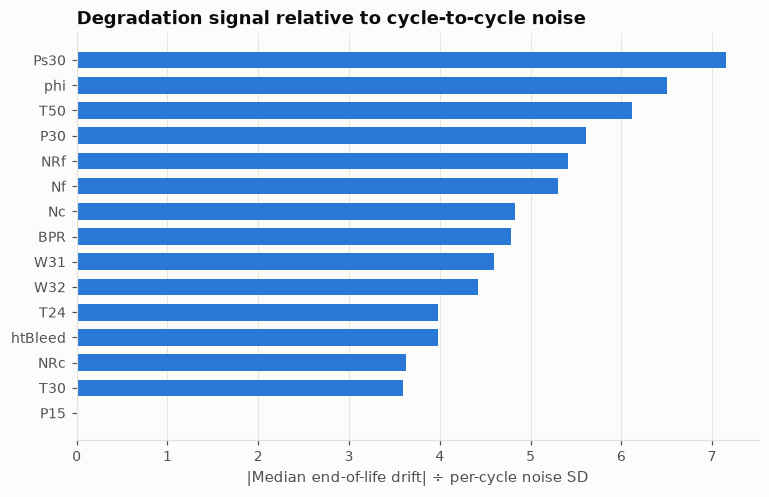

,noise SD,median drift,|drift| / noise
P15,0.0013,0.0000,0.0000
T30,4.0005,14.3582,3.5891
NRc,3.1489,11.4280,3.6292
htBleed,0.9467,3.7667,3.9788
T24,0.3019,1.2015,3.9793
W32,0.0603,-0.2663,4.4184
W31,0.1010,-0.4643,4.5975
BPR,0.0202,0.0965,4.7824
Nc,4.1746,20.1580,4.8288
Nf,0.0303,0.1603,5.2975


In [36]:
def signal_to_noise(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    # Noise: SD of cycle-to-cycle differences / √2 (slow trend cancels out; differencing doubles the noise variance).
    noise = df.groupby("unit_id")[sensors].diff().std() / np.sqrt(2)
    # Signal: median per-engine change between early life and the last 10 cycles.
    early = df[df["cycle"] <= EARLY_LIFE_CYCLES].groupby("unit_id")[sensors].mean()
    late = df[df[TARGET] < 10].groupby("unit_id")[sensors].mean()
    drift = (late - early).median()
    return pd.DataFrame({"noise SD": noise, "median drift": drift, "|drift| / noise": drift.abs() / noise})


snr = signal_to_noise(train_df, ACTIVE_SENSORS).sort_values("|drift| / noise")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(snr.index, snr["|drift| / noise"], color=SERIES[0], height=0.66)
ax.set(title="Degradation signal relative to cycle-to-cycle noise",
       xlabel="|Median end-of-life drift| ÷ per-cycle noise SD")
ax.grid(axis="y", visible=False)
save_figure(fig, "06_signal_to_noise")
plt.show()
snr.round(4)

**What does this tell us?**

- Over a whole lifetime, the best sensors drift **6–7× their per-cycle noise** (`Ps30` 7.2, `phi` 6.5, `T50` 6.1). The weakest active sensors drift only **3.6×** (`T30`, `NRc`). `P15`'s median drift is 0 at its resolution.
- That ratio is for the *entire* life. **Between neighbouring cycles, noise dominates**: no single reading tells you much. This is the quantitative reason for the smoothing and trend features in Section 8. Averaging *k* cycles reduces noise by roughly √*k* without delaying the response as much as a longer window would.

### 6.7 Correlation structure and redundancy

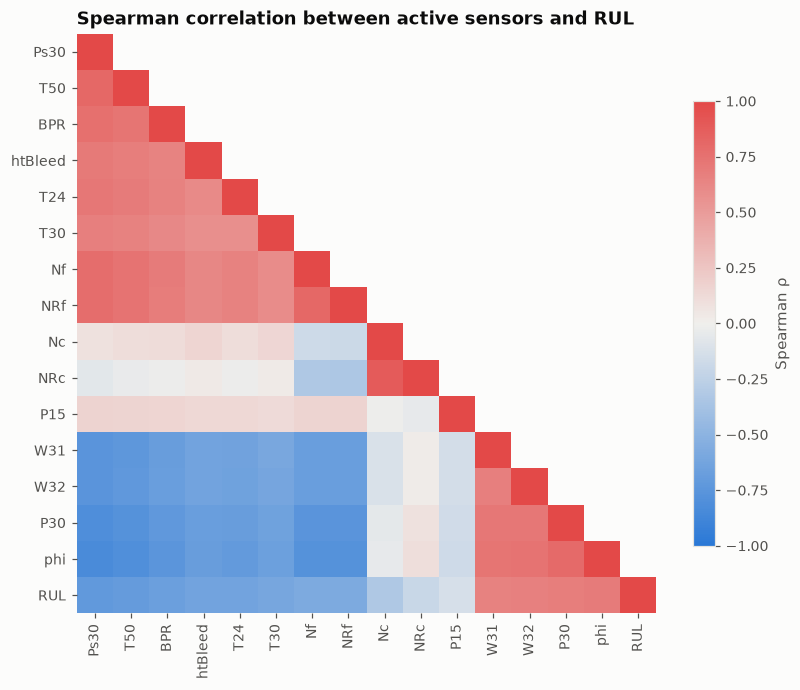

,sensor A,sensor B,Spearman ρ
0,Nc,NRc,0.8861
1,Ps30,phi,-0.8318
2,Ps30,T50,0.8116
3,Nf,NRf,0.8075
4,Ps30,P30,-0.8060
5,T50,phi,-0.7998
6,P30,phi,0.7942
7,Ps30,Nf,0.7772
8,NRf,phi,-0.7767
9,Ps30,NRf,0.7759


In [37]:
from matplotlib.colors import LinearSegmentedColormap

DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [SERIES[0], "#f0efec", "#e34948"])
heatmap_order = rul_relationship.drop(index="cycle").sort_values("Spearman ρ").index.tolist() + [TARGET]
corr = train_df[heatmap_order].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(np.ma.masked_where(mask, corr), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(heatmap_order)), heatmap_order, rotation=90)
ax.set_yticks(range(len(heatmap_order)), heatmap_order)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Spearman correlation between active sensors and RUL")
save_figure(fig, "06_correlation_heatmap")
plt.show()


def top_pairs(corr_matrix: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    pairs = upper.stack().rename("Spearman ρ").reset_index()
    pairs.columns = ["sensor A", "sensor B", "Spearman ρ"]
    return pairs.reindex(pairs["Spearman ρ"].abs().sort_values(ascending=False).index).head(n).reset_index(drop=True)


top_pairs(corr.drop(index=TARGET, columns=TARGET))

**What does this tell us?**

- Apart from `Nc`, `NRc` and `P15`, the sensors form **one large correlated block**. Everything that rises with wear correlates positively with everything else that rises, and negatively with `P30`, `phi`, `W31` and `W32`. There is essentially **one dominant degradation signal**, measured many times with independent noise. That is useful, because combining the measurements averages out noise, but it also means the sensors are heavily **redundant**.
- **`Nc`–`NRc` (ρ = 0.89)** is the most redundant pair: corrected core speed is physical core speed adjusted for inlet conditions, and FD001's inlet conditions are constant. **`Nf`–`NRf` (0.81)** follow the same logic. Both pairs sit *outside* the main block: `Nc` and `NRc` hardly correlate with the other sensors, consistent with their engine-dependent behaviour.
- **`Ps30`, `phi`, `T50` and `P30`** correlate at |ρ| ≈ 0.79–0.83 with each other. They are distinct physical quantities driven by the same compressor degradation.
- Pooled correlations mix differences between engines with changes within an engine, so high correlation here means *redundant for this fleet*, not *physically identical*.
- Redundancy does not automatically mean a feature should be dropped: averaging correlated but independently noisy sensors improves signal-to-noise. How to handle it is decided in Section 9, using mutual information and redundancy together.

### 6.8 EDA summary: what we now know about each sensor

| Group | Sensors | Evidence | Carried forward |
|---|---|---|---|
| **Strong, consistent degradation** | `Ps30`, `T50`, `phi`, `P30`, `BPR`, `W31`, `W32`, `T24`, `htBleed`, `T30` | Same direction in 100% of engines; median \|ρ\| with cycle 0.64–0.82; pooled \|ρ\| with RUL 0.61–0.72 | Primary candidates for temporal features |
| **Consistent, but a redundant pair** | `Nf` ≈ `NRf` | Consistent direction; ρ = 0.81 with each other; coarse resolution | Candidates; keep one or both, decided in Section 9 |
| **Engine-dependent direction** | `Nc` ≈ `NRc` | Direction flips in 29–40% of engines; weak pooled ρ with RUL (−0.32 / −0.20); ρ = 0.89 with each other | Evaluated in Section 9; raw level unlikely to help, rate of change may |
| **Little information** | `P15` | Two values; never changes in 38% of engines; median drift 0 | Strong removal candidate, confirmed in Section 9 |
| **Not yet assessed** | `op_setting_1`, `op_setting_2` | — | Section 7 |

**Overall findings:**

1. Degradation is a **shared, curved pattern** that becomes visible roughly **120–160 cycles before failure**.
2. Single readings are **noise-dominated**, so the signal has to be accumulated over several cycles.
3. Engines start at **different healthy baselines**, so change relative to an engine's own history matters.
4. The informative sensors are **highly redundant**.

Each finding motivates a specific choice in Sections 8–9, and the capping evidence feeds the target decision in Section 13.

## 7. Operating-condition analysis

**Why this matters.** In C-MAPSS, the operational settings shift engine operating points, and the readme warns that they *"have a substantial effect on engine performance"*. In the multi-condition subsets (FD002, FD004) a sensor change can simply mean the aircraft is flying at a different condition, not that the engine is wearing. There, sensors are normalised per operating condition before degradation can be seen.

FD001 is documented as a **single** condition. That claim needs checking, and the two settings still left after Section 3 (`op_setting_1`, `op_setting_2`) need assessing: do they describe different operating regimes, do they move sensors, and do they relate to wear?

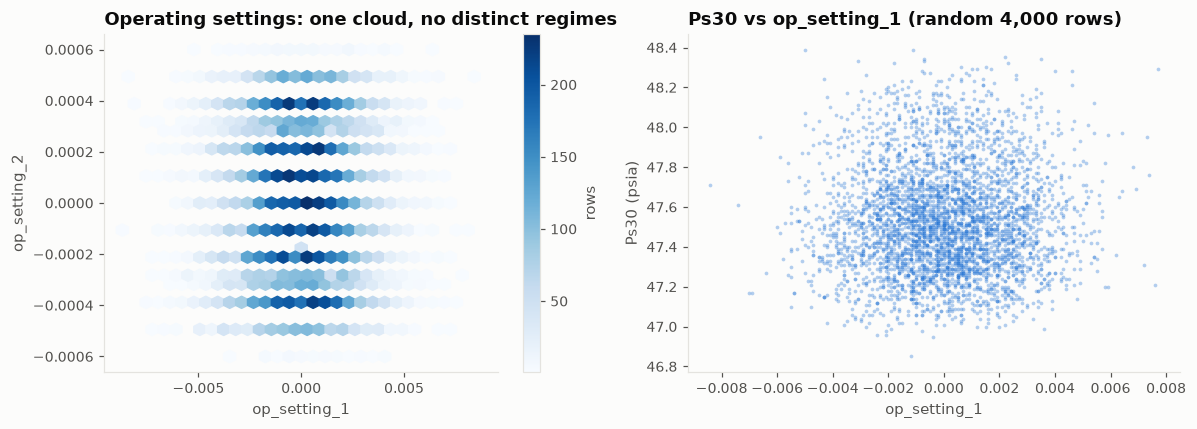

,count,mean,std,min,25%,50%,75%,max
op_setting_1,"20,631.0000",-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,"20,631.0000",0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hb = axes[0].hexbin(train_df["op_setting_1"], train_df["op_setting_2"], gridsize=30, cmap="Blues", mincnt=1)
axes[0].set(title="Operating settings: one cloud, no distinct regimes",
            xlabel="op_setting_1", ylabel="op_setting_2")
axes[0].locator_params(axis="x", nbins=5)
fig.colorbar(hb, ax=axes[0], label="rows")

sample = train_df.sample(4000, random_state=RANDOM_STATE)
axes[1].scatter(sample["op_setting_1"], sample["Ps30"], s=6, color=SERIES[0], alpha=0.35, linewidth=0)
axes[1].set(title="Ps30 vs op_setting_1 (random 4,000 rows)", xlabel="op_setting_1", ylabel="Ps30 (psia)")
for ax in axes:
    ax.grid(False)
fig.tight_layout()
save_figure(fig, "07_operating_settings")
plt.show()
train_df[ACTIVE_SETTINGS].describe().T

In [39]:
from sklearn.linear_model import LinearRegression


def setting_effect(df: pd.DataFrame, sensors: list[str], settings: list[str]) -> pd.DataFrame:
    # Share of each sensor's variance explained by the settings (linear R²), and the largest rank correlation.
    X = df[settings].to_numpy()
    rows = {}
    for sensor in sensors:
        y = df[sensor].to_numpy()
        rows[sensor] = {
            "R² (sensor ~ settings)": LinearRegression().fit(X, y).score(X, y),
            "max |Spearman ρ| with a setting": df[settings].corrwith(df[sensor], method="spearman").abs().max(),
        }
    return pd.DataFrame(rows).T


setting_effects = setting_effect(train_df, OUTLIER_SENSORS, ACTIVE_SETTINGS)
settings_profile = pd.DataFrame({
    "Spearman ρ with RUL": train_df[ACTIVE_SETTINGS].corrwith(train_df[TARGET], method="spearman"),
    "median within-engine lag-1 autocorrelation": [
        train_df.groupby("unit_id")[s].apply(lambda x: x.autocorr(1)).median() for s in ACTIVE_SETTINGS
    ],
})
print(f"Correlation between the two settings: {train_df['op_setting_1'].corr(train_df['op_setting_2']):.3f}")
print(f"Largest R² of any sensor on the settings: {setting_effects['R² (sensor ~ settings)'].max():.5f}")
display(settings_profile)
with pd.option_context("display.float_format", lambda v: f"{v:.5f}"):
    display(setting_effects.sort_values("R² (sensor ~ settings)", ascending=False))

Correlation between the two settings: 0.012
Largest R² of any sensor on the settings: 0.00036


,Spearman ρ with RUL,median within-engine lag-1 autocorrelation
op_setting_1,-0.0013,-0.0037
op_setting_2,-0.0038,-0.0120


,R² (sensor ~ settings),max |Spearman ρ| with a setting
P30,0.00036,0.01709
NRf,0.00033,0.01932
T50,0.00030,0.01660
W32,0.00027,0.01091
Ps30,0.00027,0.01222
BPR,0.00026,0.01438
Nf,0.00018,0.01276
htBleed,0.00016,0.01285
W31,0.00014,0.01114
T24,0.00013,0.00866


**What does this tell us?**

- **There is one operating regime.** The two settings form a single compact cloud centred on zero (`op_setting_1` within ±0.0087, `op_setting_2` within ±0.0006), with no clusters. This confirms the readme's "ONE (Sea Level)" condition from the data itself.
- **The settings do not move the sensors.** The largest share of any sensor's variance they explain is **R² ≈ 0.0004**, and no rank correlation exceeds 0.02. The `Ps30` scatter shows no slope at all.
- **They behave like random noise.** Their lag-1 autocorrelation within an engine is about 0: a setting at one cycle says nothing about the next. They are also uncorrelated with each other (0.012) and with RUL (|ρ| < 0.005).

A caveat: a linear R² can miss non-linear effects. But with rank correlations also at about 0, and the visual check showing no structure, nothing points to a hidden relationship. Section 9 adds a non-linear test (mutual information).

**Decisions:**

1. **No operating-condition normalisation.** Per-condition normalisation removes the sensor shift caused by each regime. With one regime and no measurable effect of the settings, it would only subtract a constant. It is the right tool for FD002/FD004, not for FD001.
2. **Sensor changes in FD001 can be attributed to degradation, not to operating conditions.** This is an association, not proof of cause: the simulator's fault injection is the documented cause, and our data only rule out operating conditions as an alternative explanation.
3. `op_setting_1` and `op_setting_2` are **strong removal candidates**. The final decision is made in Section 9, alongside the mutual-information evidence.

## 8. Feature engineering: degradation-aware temporal features

**What the EDA asked for.** Each feature family below answers a specific finding from Section 6:

| EDA finding | Consequence | Feature family |
|---|---|---|
| Single readings are noise-dominated (6.6) | Accumulate the signal over recent cycles | **Rolling mean**, **exponentially weighted mean (EWM)** |
| Degradation accelerates near failure (6.1, 6.5) | How *fast* a sensor is changing carries information beyond its level | **Rolling slope** |
| Engines start at different healthy levels (6.2) | Measure drift *relative to the engine's own early life* | **Delta from early-life baseline** |
| Twelve sensors share one consistent degradation direction (6.3, 6.7) | Combine them to average out independent noise | **Composite health index** |

**Rules for every feature:**

1. **Within one engine only.** Every calculation is grouped by `unit_id`, so engine A's readings can never enter engine B's features.
2. **Past and present only.** A feature at cycle *t* uses readings at cycles ≤ *t*. All windows are trailing, never centred.
3. **Usable from the first cycle.** At the start of an engine, windows simply contain fewer cycles (e.g. the 10-cycle mean at cycle 3 averages 3 readings). This keeps every row, which matters because test engines can be as short as 31 cycles and a model must be able to score an engine at any age. The one exception is the slope: a straight line fitted to 2–3 noisy points is meaningless, so it is reported as 0 until 10 cycles exist (see 8.3).

Both rules 1 and 2 are **verified programmatically** in Section 8.4, not just assumed.

### 8.1 Which candidate families were screened out

Before building the final set, we screened a wider set of common temporal transforms on the training data. For each family, the table shows the median absolute Spearman correlation with RUL across the 14 continuous sensors. This is a *coarse screen* to avoid building families that are clearly redundant or empty. The detailed selection happens in Section 9.

In [40]:
SCREEN_WINDOW = 10


def screen_feature_families(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    by_engine = df.groupby("unit_id")
    rows, redundancy = {}, {}
    for sensor in sensors:
        g = by_engine[sensor]
        trailing = lambda f: g.transform(lambda x: getattr(x.rolling(SCREEN_WINDOW, min_periods=1), f)())
        families = {
            "raw reading": df[sensor],
            "lag 1": g.shift(1),
            "first difference": g.diff(),
            "percentage change": g.pct_change(),
            f"rolling mean ({SCREEN_WINDOW})": trailing("mean"),
            f"rolling min ({SCREEN_WINDOW})": trailing("min"),
            f"rolling max ({SCREEN_WINDOW})": trailing("max"),
            f"rolling std ({SCREEN_WINDOW})": g.transform(lambda x: x.rolling(SCREEN_WINDOW, min_periods=2).std()),
            "expanding (cumulative) mean": g.transform(lambda x: x.expanding().mean()),
        }
        rows[sensor] = {name: abs(values.corr(df[TARGET], method="spearman")) for name, values in families.items()}
        redundancy[sensor] = {
            "rolling min vs rolling mean": families[f"rolling min ({SCREEN_WINDOW})"].corr(families[f"rolling mean ({SCREEN_WINDOW})"], method="spearman"),
            "rolling max vs rolling mean": families[f"rolling max ({SCREEN_WINDOW})"].corr(families[f"rolling mean ({SCREEN_WINDOW})"], method="spearman"),
            "percentage change vs first difference": families["percentage change"].corr(families["first difference"], method="spearman"),
            "lag 1 vs raw reading": families["lag 1"].corr(families["raw reading"], method="spearman"),
        }
    return pd.DataFrame(rows).T, pd.DataFrame(redundancy).T


family_screen, family_redundancy = screen_feature_families(train_df, OUTLIER_SENSORS)
display(family_screen.median().sort_values(ascending=False).rename("median |Spearman ρ| with RUL").to_frame())
family_redundancy.median().rename("median Spearman ρ between the two").to_frame()

,median |Spearman ρ| with RUL
rolling mean (10),0.7441
rolling max (10),0.6975
rolling min (10),0.6860
raw reading,0.6414
lag 1,0.6363
expanding (cumulative) mean,0.3806
rolling std (10),0.0606
first difference,0.0189
percentage change,0.0178


,median Spearman ρ between the two
rolling min vs rolling mean,0.9594
rolling max vs rolling mean,0.9601
percentage change vs first difference,1.0000
lag 1 vs raw reading,0.7720


**Result and decisions:**

| Family | Median \|ρ\| | Decision | Reason |
|---|---|---|---|
| Rolling mean (10) | **0.74** | **Keep** | Clearly better than the raw reading (0.64): averaging 10 cycles cuts noise by about √10 |
| Rolling max / min (10) | 0.70 / 0.69 | Drop | Both correlate ρ ≈ 0.96 with the rolling mean and are weaker. For a noisy monotonic signal they are just a noisier estimate of the level |
| Raw reading | 0.64 | Keep the raw sensors as a baseline | Needed for the raw-vs-engineered comparison in Section 9 |
| Lag 1 | 0.64 | Drop | Just the previous noisy reading (ρ ≈ 0.77 with the current one, slightly weaker against RUL). Any information it holds is captured better by the rolling mean, which averages the last 10 readings |
| Expanding mean | 0.38 | Drop | Averages the long healthy period into every value, diluting recent degradation |
| Rolling std (10) | 0.06 | Drop | Measurement noise does not grow noticeably as engines wear in FD001, so dispersion carries almost no RUL signal |
| First difference / % change | 0.02 | Drop | Pure noise: cycle-to-cycle change is dominated by sensor noise (Section 6.6). The two are also identical in rank (sensor levels are far from zero, so % change ≈ difference ÷ constant) |

Trend information is not lost by dropping first differences: the **rolling slope** below estimates the rate of change over 20 cycles, which averages the noise out.

**Window length.** On the training data, the rolling mean's correlation with RUL rises from window 1 to a peak around **5–10 cycles** and then slowly falls (e.g. `Ps30`: 0.72 → 0.75 → 0.71 at 30 cycles), because longer windows react more slowly to late-life acceleration. We use **10 cycles** for the mean and an EWM span of 10. The slope uses **20 cycles**, because a slope estimate is much noisier than a mean and needs a longer base. These are reasonable, documented defaults. Tuning them properly belongs in engine-grouped cross-validation during modelling.

In [41]:
ROLL_WINDOW = 10
EWM_SPAN = 10
SLOPE_WINDOW = 20
SLOPE_MIN_CYCLES = 10  # fewer points give unstable slopes (see 8.3); report 0 until then
BASELINE_CYCLES = 10
TEMPORAL_SENSORS = OUTLIER_SENSORS  # 14 continuous sensors (P15 excluded: two-valued, see 3.2)


def rolling_slope(values: pd.Series, window: int, min_cycles: int) -> pd.Series:
    # Least-squares slope (units per cycle) over the trailing window, from rolling moments.
    # 0 ("no measurable trend yet") until min_cycles readings exist.
    t = pd.Series(np.arange(len(values), dtype=float), index=values.index)
    roll = lambda s: s.rolling(window, min_periods=min_cycles).mean()
    covariance = roll(t * values) - roll(t) * roll(values)
    variance = roll(t * t) - roll(t) ** 2
    return (covariance / variance).fillna(0.0)


def build_temporal_features(df: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    if not df.equals(df.sort_values(["unit_id", "cycle"])):
        raise ValueError("rows must be sorted by unit_id, cycle before building temporal features")
    by_engine = df.groupby("unit_id", sort=False)
    is_baseline_cycle = df["cycle"] <= BASELINE_CYCLES
    features = {}
    for s in sensors:
        g = by_engine[s]
        ewm = g.transform(lambda x: x.ewm(span=EWM_SPAN).mean())
        # Mean of the engine's own first BASELINE_CYCLES readings (expanding while fewer exist).
        baseline = df[s].where(is_baseline_cycle).groupby(df["unit_id"]).transform(lambda x: x.expanding().mean())
        features[f"{s}_mean{ROLL_WINDOW}"] = g.transform(lambda x: x.rolling(ROLL_WINDOW, min_periods=1).mean())
        features[f"{s}_ewm{EWM_SPAN}"] = ewm
        features[f"{s}_slope{SLOPE_WINDOW}"] = g.transform(lambda x: rolling_slope(x, SLOPE_WINDOW, SLOPE_MIN_CYCLES))
        features[f"{s}_delta"] = ewm - baseline
    return pd.concat([df, pd.DataFrame(features, index=df.index)], axis=1)

### 8.2 Composite health index

The twelve consistently trending sensors (Section 6.3) are combined into one indicator. Each sensor's **delta from its early-life baseline** is divided by that sensor's early-life noise level, its sign is flipped so that "worse" is always positive, and the twelve are averaged:

$$\text{HI}_t = \frac{1}{12}\sum_{s} d_s \cdot \frac{\text{delta}_{s,t}}{\sigma_s^{\text{early}}}$$

Here $d_s$ is the wear direction (+1 rising, −1 falling) and $\sigma_s^{\text{early}}$ is the SD over the first 30 cycles of every engine.

Both $d_s$ and $\sigma_s$ are **estimated from training engines only** and then applied unchanged to test engines, the same way a fitted scaler is used. Neither uses RUL. $d_s$ comes from each sensor's correlation with *cycle* inside each engine (Section 6.3), not from the target.

In [42]:
HI_SENSORS = CONSISTENT_SENSORS


def fit_health_index(train: pd.DataFrame) -> dict:
    early = train.loc[train["cycle"] <= EARLY_LIFE_CYCLES, HI_SENSORS]
    return {"direction": wear_direction[HI_SENSORS], "early_sd": early.std()}


def add_health_index(df: pd.DataFrame, params: dict) -> pd.DataFrame:
    deltas = df[[f"{s}_delta" for s in HI_SENSORS]].set_axis(HI_SENSORS, axis=1)
    return df.assign(health_index=(deltas / params["early_sd"] * params["direction"]).mean(axis=1))


health_index_params = fit_health_index(train_df)
train_features = add_health_index(build_temporal_features(train_df, TEMPORAL_SENSORS), health_index_params)
test_features = add_health_index(build_temporal_features(test_df, TEMPORAL_SENSORS), health_index_params)

ENGINEERED_FEATURES = [c for c in train_features.columns if c not in train_df.columns]
assert_no_target_leakage(ENGINEERED_FEATURES)
print(f"train: {train_df.shape} -> {train_features.shape} | test: {test_df.shape} -> {test_features.shape}")
print(f"{len(ENGINEERED_FEATURES)} engineered features = {len(TEMPORAL_SENSORS)} sensors × 4 families + health_index")

train: (20631, 20) -> (20631, 77) | test: (13096, 20) -> (13096, 77)
57 engineered features = 14 sensors × 4 families + health_index


### 8.3 What the engineered features look like

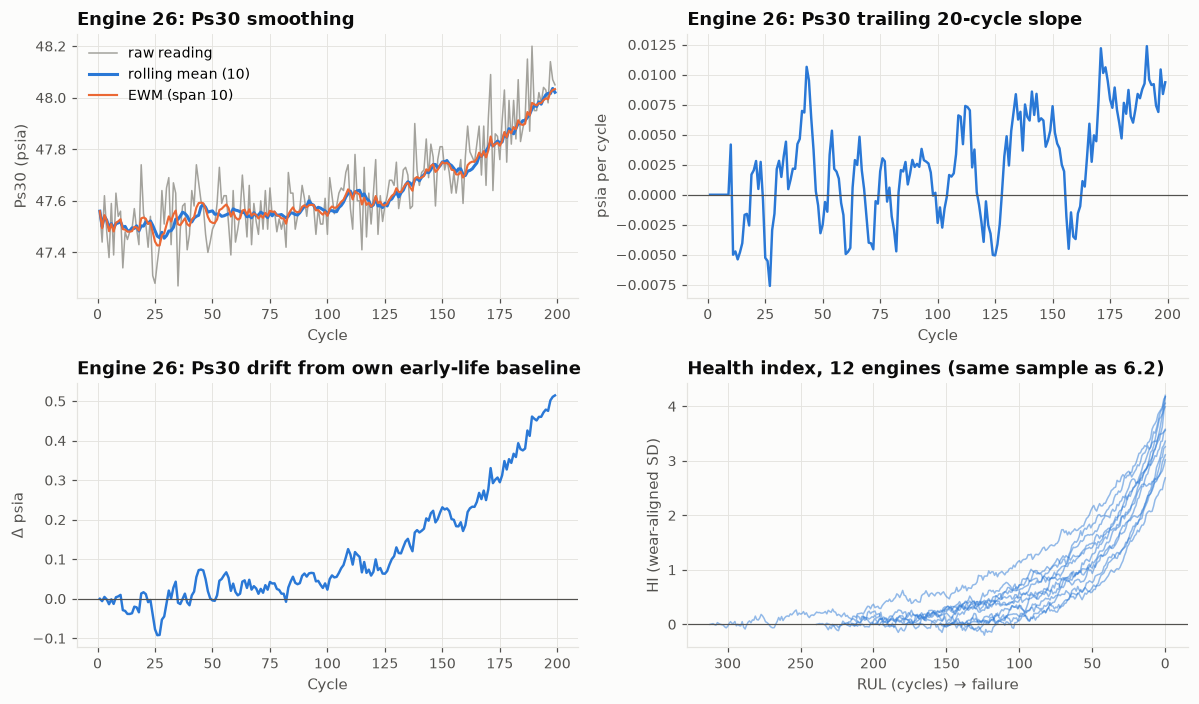

In [43]:
example = train_features[train_features["unit_id"] == median_engine]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))

ax = axes[0, 0]
ax.plot(example["cycle"], example["Ps30"], color=NEUTRAL, linewidth=1, label="raw reading")
ax.plot(example["cycle"], example[f"Ps30_mean{ROLL_WINDOW}"], color=SERIES[0], linewidth=2, label=f"rolling mean ({ROLL_WINDOW})")
ax.plot(example["cycle"], example[f"Ps30_ewm{EWM_SPAN}"], color=SERIES[1], linewidth=1.4, label=f"EWM (span {EWM_SPAN})")
ax.set(title=f"Engine {median_engine}: Ps30 smoothing", xlabel="Cycle", ylabel="Ps30 (psia)")
ax.legend(loc="upper left")

ax = axes[0, 1]
ax.plot(example["cycle"], example[f"Ps30_slope{SLOPE_WINDOW}"], color=SERIES[0])
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.set(title=f"Engine {median_engine}: Ps30 trailing {SLOPE_WINDOW}-cycle slope", xlabel="Cycle", ylabel="psia per cycle")

ax = axes[1, 0]
ax.plot(example["cycle"], example["Ps30_delta"], color=SERIES[0])
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.set(title=f"Engine {median_engine}: Ps30 drift from own early-life baseline", xlabel="Cycle", ylabel="Δ psia")

ax = axes[1, 1]
for unit in sample_engines:
    engine = train_features[train_features["unit_id"] == unit]
    ax.plot(engine[TARGET], engine["health_index"], color=SERIES[0], alpha=0.5, linewidth=1)
ax.invert_xaxis()
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.set(title="Health index, 12 engines (same sample as 6.2)", xlabel="RUL (cycles) → failure", ylabel="HI (wear-aligned SD)")
fig.tight_layout()
save_figure(fig, "08_engineered_features")
plt.show()

In [44]:
def family_of(feature: str) -> str:
    for suffix, family in [(f"_mean{ROLL_WINDOW}", "rolling mean"), (f"_ewm{EWM_SPAN}", "EWM"),
                           (f"_slope{SLOPE_WINDOW}", "rolling slope"), ("_delta", "delta from baseline")]:
        if feature.endswith(suffix):
            return family
    return "health index" if feature == "health_index" else "raw sensor"


family_strength = pd.DataFrame({
    "feature": TEMPORAL_SENSORS + ENGINEERED_FEATURES,
    "|Spearman ρ| with RUL": train_features[TEMPORAL_SENSORS + ENGINEERED_FEATURES].corrwith(
        train_features[TARGET], method="spearman").abs().to_numpy(),
})
family_strength["family"] = family_strength["feature"].map(family_of)
(family_strength.groupby("family")["|Spearman ρ| with RUL"]
 .agg(["median", "max", "count"]).sort_values("median", ascending=False))

,median,max,count
family,,,
health index,0.8868,0.8868,1
delta from baseline,0.7822,0.8644,14
EWM,0.7442,0.7536,14
rolling mean,0.7441,0.7530,14
raw sensor,0.6414,0.7181,14
rolling slope,0.4231,0.5422,14


**What does this tell us?**

- **Smoothing works as intended.** The rolling mean and EWM follow the trend through the noise. The EWM is slightly more responsive, and correspondingly slightly noisier, because it weights recent cycles more. The two are close, and Section 9 will probably keep only one.
- **The slope stays close to zero for most of life and turns consistently positive in the last ~40 cycles.** It is still noisy: a 20-cycle slope of a noisy signal is a much rougher estimate than a mean.
- **Warm-up issue found and fixed.** The first version fitted slopes from 2 cycles onwards, and this chart showed large spurious values in the first few cycles (−0.12 psia/cycle at cycle 2, about 10× the real late-life slope): a line through 2–3 noisy points is mostly noise. The slope now requires at least 10 readings and is 0 before that, which is visible as the flat start. This explains why its correlation with RUL is lower than that of the level features. Its value lies in *when* it changes.
- **The delta from baseline starts at exactly 0** for every engine and measures how far the engine has moved from its own starting point. This removes the engine-to-engine offsets seen in 6.2.
- **The health index stays near 0 for most of life and rises steeply towards failure, consistently across engines.** It condenses twelve sensors into one curve with far less noise than any single sensor.
- **Delta from baseline (median |ρ| 0.78) beats the plain level features (0.74)**, and the **health index (0.89) is the strongest single feature**. Removing each engine's starting offset and combining sensors both pay off, as Section 6 predicted.
- The family table gives a first ranking, but **correlation is only one view**. The slope, for example, adds information *on top of* the level features rather than replacing them. Section 9 assesses features jointly (redundancy, mutual information), not one at a time.

### 8.4 Verifying: no cross-engine contamination, no future information

Three automated tests, each designed to **fail** if a feature leaks:

1. **Engine isolation.** Rebuild the features for every engine *on its own* (a dataframe containing only that engine) and compare with the grouped result. Any difference would mean another engine's rows influenced the values.
2. **Future truncation.** Cut every engine at a random cycle, rebuild, and compare the surviving rows. If a feature used later cycles, removing them would change earlier values.
3. **Future perturbation.** Replace every reading *after* a random cutoff with extreme values (×1000) and check that features at or before the cutoff are unchanged.

In [45]:
FEATURE_TOLERANCE = 1e-9


def max_abs_difference(a: pd.DataFrame, b: pd.DataFrame) -> float:
    return float((a[ENGINEERED_FEATURES] - b.loc[a.index, ENGINEERED_FEATURES]).abs().max().max())


def rebuild(df: pd.DataFrame) -> pd.DataFrame:
    return add_health_index(build_temporal_features(df, TEMPORAL_SENSORS), health_index_params)


# 1. Engine isolation
isolated = pd.concat([rebuild(engine) for _, engine in train_df.groupby("unit_id")])
isolation_diff = max_abs_difference(isolated, train_features)

# 2. Future truncation: keep each engine's first k cycles (k random per engine)
rng = np.random.default_rng(RANDOM_STATE)
cutoff = pd.Series(rng.integers(2, train_life.to_numpy()), index=train_life.index)
keep = train_df["cycle"] <= train_df["unit_id"].map(cutoff)
truncation_diff = max_abs_difference(rebuild(train_df[keep]), train_features)

# 3. Future perturbation: corrupt every sensor reading after the cutoff
corrupted = train_df.copy()
corrupted.loc[~keep, TEMPORAL_SENSORS] *= 1000
perturbation_diff = max_abs_difference(rebuild(corrupted)[keep], train_features)

# 4. Boundary values: each engine's first row can only reflect its own first reading
first_rows = train_features.groupby("unit_id").head(1)
boundary_ok = (
    np.allclose(first_rows[[f"{s}_mean{ROLL_WINDOW}" for s in TEMPORAL_SENSORS]].to_numpy(), first_rows[TEMPORAL_SENSORS].to_numpy())
    and (first_rows[[f"{s}_slope{SLOPE_WINDOW}" for s in TEMPORAL_SENSORS] + [f"{s}_delta" for s in TEMPORAL_SENSORS]] == 0).all().all()
)

leakage_tests = pd.DataFrame({
    "max |difference|": [isolation_diff, truncation_diff, perturbation_diff, np.nan],
    "passed": [isolation_diff < FEATURE_TOLERANCE, truncation_diff < FEATURE_TOLERANCE,
               perturbation_diff < FEATURE_TOLERANCE, boundary_ok],
}, index=["engine isolation", "future truncation", "future perturbation (×1000)", "first-row boundary values"])
assert leakage_tests["passed"].all(), "feature leakage detected"
leakage_tests

,max |difference|,passed
engine isolation,0.0000,True
future truncation,0.0000,True
future perturbation (×1000),0.0000,True
first-row boundary values,NaN,True


**Result.** All four tests pass. The differences are zero up to floating-point rounding (tolerance 10⁻⁹):

- Features computed on each engine alone are identical to the grouped computation, so **no information crosses engine boundaries**.
- Deleting or corrupting every reading after a cutoff, even multiplying it by 1000, leaves all earlier feature values unchanged, so **no feature uses future cycles**.
- At each engine's first cycle, the rolling mean equals the raw reading and the slope and delta are 0. Nothing carries over from the previous engine in the file.

The perturbation test also shows that the health index's fitted parameters come from the original training data, not from rows being scored.

### 8.5 Feature-engineering summary

| Family | Features | Window | Degradation meaning |
|---|---|---|---|
| Rolling mean | 14 | trailing 10 cycles | Current sensor level with noise reduced about 3× |
| EWM | 14 | span 10 | Current level, weighted towards the most recent cycles, so it reacts faster to acceleration |
| Rolling slope | 14 | trailing 20 cycles (≥ 10 needed) | Rate of degradation: how fast the sensor is moving now |
| Delta from baseline | 14 | vs the engine's first 10 cycles | How far *this* engine has moved from its own healthy state (removes initial-wear offsets) |
| Health index | 1 | — | Twelve consistent sensors combined into one low-noise wear indicator |
| **Total engineered** | **57** | | |

Together with the 14 continuous raw sensors, `P15`, the 2 settings and `cycle`, this gives **75 candidate inputs**. That is deliberately compact: four families with a stated purpose rather than every transform at several window lengths. Section 9 reduces it to a final shortlist.

## 9. Feature selection

**What / why.** There are 75 candidate inputs, many of them measuring the same degradation signal (Section 6.7). Redundant and empty features make models slower, harder to interpret and easier to overfit. The aim is a **short list that keeps the information and drops the repetition**.

**Approach.** Several complementary views are combined, because no single criterion is enough:

1. **Relevance:** Spearman correlation (monotonic) *and* mutual information (any dependence, including non-linear) with the target.
2. **Redundancy:** correlation between features, both by family and by clustering.
3. **Domain reasoning:** physical duplicates (physical vs corrected speeds), and what each family is supposed to capture.
4. **A grouped cross-validation diagnostic** to check that removing a group of features does not remove information.

**Selection target.** Section 6.5 showed that the sensors cannot distinguish RUL 300 from RUL 200. Features are therefore scored against a **capped RUL** of 125 cycles (the lower end of the 125–150 range supported by 6.5, and a common choice for FD001). For comparison, scores against the uncapped RUL are shown alongside. The definitive target decision is made in Section 13.

> **Everything in this section uses training engines only.** Selection decisions are themselves fitted to data, so they must never see the test set.

In [46]:
from sklearn.feature_selection import mutual_info_regression

RUL_CAP = 125
ALL_CANDIDATES = ["cycle"] + ACTIVE_SETTINGS + ACTIVE_SENSORS + ENGINEERED_FEATURES
assert_no_target_leakage(ALL_CANDIDATES)

y_capped = train_features[TARGET].clip(upper=RUL_CAP)
X_candidates = train_features[ALL_CANDIDATES]

relevance = pd.DataFrame({
    "family": [family_of(f) if f in ENGINEERED_FEATURES + TEMPORAL_SENSORS else ("setting" if f in ACTIVE_SETTINGS else f) for f in ALL_CANDIDATES],
    "MI (capped RUL)": mutual_info_regression(X_candidates, y_capped, random_state=RANDOM_STATE),
    "MI (uncapped RUL)": mutual_info_regression(X_candidates, train_features[TARGET], random_state=RANDOM_STATE),
    "|Spearman ρ| (capped)": X_candidates.corrwith(y_capped, method="spearman").abs().to_numpy(),
}, index=ALL_CANDIDATES)
relevance.loc["P15", "family"] = "raw sensor (NZV)"
relevance.sort_values("MI (capped RUL)", ascending=False).head(15)

,family,MI (capped RUL),MI (uncapped RUL),|Spearman ρ| (capped)
health_index,health index,0.8261,0.8688,0.8870
Ps30_delta,delta from baseline,0.7560,0.7986,0.8621
T50_delta,delta from baseline,0.7298,0.7566,0.8510
BPR_delta,delta from baseline,0.6849,0.7164,0.8274
W32_delta,delta from baseline,0.6756,0.6986,0.8284
phi_delta,delta from baseline,0.6550,0.6823,0.8316
W31_delta,delta from baseline,0.6418,0.6656,0.8131
Ps30_ewm10,EWM,0.6337,0.6845,0.7496
T50_ewm10,EWM,0.6270,0.6694,0.7546
cycle,cycle,0.6264,0.8866,0.7776


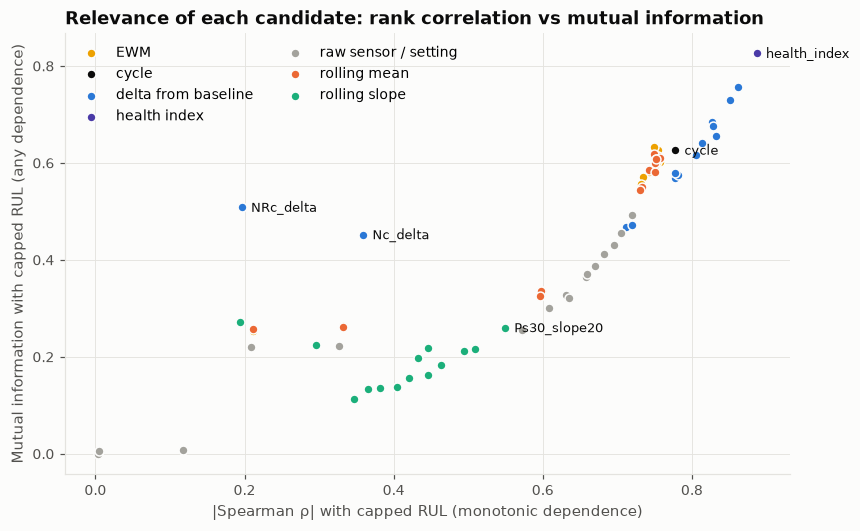

,family,MI (capped RUL),MI (uncapped RUL),|Spearman ρ| (capped)
NRc_delta,delta from baseline,0.5086,0.5466,0.1965
Nc_delta,delta from baseline,0.4522,0.4951,0.3593
cycle,cycle,0.6264,0.8866,0.7776
P15,raw sensor (NZV),0.0071,0.0085,0.1173
op_setting_1,setting,0.0000,0.0011,0.0035
op_setting_2,setting,0.0059,0.0062,0.0045


In [47]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
family_colors = {"health index": SERIES[6], "delta from baseline": SERIES[0], "rolling mean": SERIES[1], "EWM": SERIES[3],
                 "rolling slope": SERIES[2], "raw sensor / setting": NEUTRAL, "cycle": INK}
plot_group = relevance["family"].replace({"raw sensor": "raw sensor / setting", "raw sensor (NZV)": "raw sensor / setting",
                                          "setting": "raw sensor / setting"})
for family, group in relevance.groupby(plot_group):
    ax.scatter(group["|Spearman ρ| (capped)"], group["MI (capped RUL)"], s=34, color=family_colors[family],
               label=family, edgecolor=SURFACE, linewidth=1, zorder=3)
for feature in ["health_index", "NRc_delta", "Nc_delta", "cycle", "Ps30_slope20"]:
    row = relevance.loc[feature]
    ax.annotate(feature, (row["|Spearman ρ| (capped)"], row["MI (capped RUL)"]), xytext=(6, -3),
                textcoords="offset points", fontsize=8.5, color=INK)
ax.set(title="Relevance of each candidate: rank correlation vs mutual information",
       xlabel="|Spearman ρ| with capped RUL (monotonic dependence)", ylabel="Mutual information with capped RUL (any dependence)")
ax.legend(loc="upper left", ncol=2)
save_figure(fig, "09_relevance_mi_vs_spearman")
plt.show()
relevance.loc[["NRc_delta", "Nc_delta", "cycle", "P15", "op_setting_1", "op_setting_2"]]

**What does this tell us?**

- **Most features lie on a common curve**: the more monotonic the relationship, the higher the mutual information. The health index and the delta features are at the top, raw sensors in the middle, and slopes lower.
- **`NRc_delta` and `Nc_delta` are far off the curve.** Their rank correlation is weak (0.20 and 0.36), but their mutual information (0.51 and 0.45) is as high as many strong sensors. This is the engine-dependent behaviour from Section 6.3: the *size* of core-speed drift grows towards failure, but its *sign* differs between engines. A large drift in either direction means little life left. That relationship is real but not monotonic, so **a correlation-only selection would wrongly discard these features.**
- **`cycle` depends heavily on how the target is defined.** Its MI is 0.63 against capped RUL but 0.89 against uncapped RUL. Uncapped RUL is *built* from cycle (RUL = lifetime − cycle), so part of that score is structural, not physical. Against the capped target, `cycle` is still informative, mainly about whether an engine is old enough to have started degrading at all.
- **`op_setting_1`, `op_setting_2` and `P15` carry essentially no information** (MI ≤ 0.007). This confirms Sections 3.2 and 7 with a non-linear test.

### 9.1 Step-by-step selection

Each step removes a group of features for a stated reason. The steps run in order, and every removal is recorded.

In [48]:
MI_FLOOR = 0.02
CLUSTER_THRESHOLD = 0.90
removal_log = {}


def remove(features, to_drop, reason):
    for f in to_drop:
        removal_log[f] = reason
    return [f for f in features if f not in to_drop]


def mean_mi(sensor):
    return relevance.loc[[f for f in relevance.index if f == sensor or f.startswith(sensor + "_")], "MI (capped RUL)"].mean()


selected = list(ALL_CANDIDATES)

# Step 1 — no information
no_info = relevance.index[relevance["MI (capped RUL)"] < MI_FLOOR].tolist()
selected = remove(selected, no_info, f"Step 1: no information (MI < {MI_FLOOR}); confirmed by Sections 3.2 / 7")

# Step 2 — family-level redundancy
mean_vs_ewm = np.median([train_features[f"{s}_mean{ROLL_WINDOW}"].corr(train_features[f"{s}_ewm{EWM_SPAN}"], method="spearman") for s in TEMPORAL_SENSORS])
raw_vs_mean = np.median([train_features[s].corr(train_features[f"{s}_mean{ROLL_WINDOW}"], method="spearman") for s in TEMPORAL_SENSORS])
selected = remove(selected, [f"{s}_ewm{EWM_SPAN}" for s in TEMPORAL_SENSORS],
                  f"Step 2: EWM duplicates the rolling mean (median ρ = {mean_vs_ewm:.3f}); rolling mean kept as the simpler definition")
selected = remove(selected, TEMPORAL_SENSORS,
                  f"Step 2: raw reading is a noisier version of its rolling mean (median ρ = {raw_vs_mean:.2f}, lower MI)")
selected = remove(selected, [f"{s}_slope{SLOPE_WINDOW}" for s in TEMPORAL_SENSORS],
                  "Step 2: slope family adds no information once levels and deltas are present (diagnostic in 9.2)")

# Step 3 — physical duplicates: physical vs corrected speeds measure the same shaft at constant inlet conditions
pair_choice = {}
for a, b in [("Nf", "NRf"), ("Nc", "NRc")]:
    keep, drop = (a, b) if mean_mi(a) >= mean_mi(b) else (b, a)
    pair_choice[f"{a}/{b}"] = f"keep {keep} (mean MI {mean_mi(keep):.3f} vs {mean_mi(drop):.3f})"
    selected = remove(selected, [f for f in selected if f.startswith(drop + "_")],
                      f"Step 3: {drop} duplicates {keep} (same shaft speed; corrected vs physical at constant inlet conditions)")
print("Step 3 choices:", pair_choice)
print(f"After steps 1–3: {len(selected)} features")

Step 3 choices: {'Nf/NRf': 'keep Nf (mean MI 0.322 vs 0.316)', 'Nc/NRc': 'keep NRc (mean MI 0.302 vs 0.284)'}
After steps 1–3: 26 features


In [49]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

# Step 4 — residual redundancy: cluster features whose |Spearman ρ| exceeds the threshold, keep the most informative one
abs_corr = train_features[selected].corr(method="spearman").abs()
clusters = fcluster(linkage(squareform(1 - abs_corr.to_numpy(), checks=False), method="average"),
                    t=1 - CLUSTER_THRESHOLD, criterion="distance")
cluster_table = []
for cluster_id in np.unique(clusters):
    members = [f for f, c in zip(selected, clusters) if c == cluster_id]
    if len(members) > 1:
        representative = max(members, key=lambda f: relevance.loc[f, "MI (capped RUL)"])
        others = [m for m in members if m != representative]
        cluster_table.append({"kept": representative, "dropped": ", ".join(others), "size": len(members)})
        selected = remove(selected, others, f"Step 4: |ρ| > {CLUSTER_THRESHOLD} with {representative}, which has higher MI")

FINAL_FEATURES = selected
assert_no_target_leakage(FINAL_FEATURES)
display(pd.DataFrame(cluster_table))
print(f"Final shortlist ({len(FINAL_FEATURES)} features):", FINAL_FEATURES)

,kept,dropped,size
0,Ps30_mean10,"T24_mean10, T30_mean10, T50_mean10, P30_mean10, phi_mean10, BPR_mean10, htBl...",10


Final shortlist (17 features): ['cycle', 'T24_delta', 'T30_delta', 'T50_delta', 'P30_delta', 'Nf_mean10', 'Nf_delta', 'Ps30_mean10', 'Ps30_delta', 'phi_delta', 'NRc_mean10', 'NRc_delta', 'BPR_delta', 'htBleed_delta', 'W31_delta', 'W32_delta', 'health_index']


**What the steps did:**

- **Step 1** removed the two operating settings and `P15`.
- **Step 2** kept one smoothed level per sensor. The rolling mean and EWM are practically identical (ρ = 0.996). The rolling mean is kept because "average of the last 10 cycles" is the simpler definition, and the grouped diagnostic below shows no difference between them. Raw readings are noisier copies of their own rolling mean. The slope family is dropped on the evidence of 9.2.
- **Step 3** kept one sensor from each physical-duplicate pair: `Nf` over `NRf`, and `NRc` over `Nc`, each by its higher mean mutual information.
- **Step 4** found one remaining redundant cluster: the ten smoothed *levels* of the main degradation block (`T24`, `T30`, `T50`, `P30`, `Ps30`, `phi`, `BPR`, `htBleed`, `W31`, `W32`) are all mutually correlated above 0.9, so `Ps30_mean10` (highest MI) represents them.

All twelve *deltas* survive. Each sensor's drift from its own baseline still carries partly independent information. This is the "same signal, independent noise" situation from 6.7, where keeping several measurements helps.

**Robustness of the selection.** Mutual information is estimated with a k-nearest-neighbour method that involves randomness. A selection that changed with the random seed would not be trustworthy, so we repeat the estimate with five seeds and check every decision that depended on it.

In [50]:
MI_SEEDS = range(5)
mi_by_seed = pd.DataFrame({seed: mutual_info_regression(X_candidates, y_capped, random_state=seed) for seed in MI_SEEDS},
                          index=ALL_CANDIDATES)
seed_mean_mi = lambda sensor: mi_by_seed.loc[[f for f in ALL_CANDIDATES if f == sensor or f.startswith(sensor + "_")]].mean()
level_block = [f"{s}_mean{ROLL_WINDOW}" for s in ["T24", "T30", "T50", "P30", "Ps30", "phi", "BPR", "htBleed", "W31", "W32"]]
robustness = pd.DataFrame({
    "decision": ["no-information features (Step 1)", "Nf kept over NRf (Step 3)", "NRc kept over Nc (Step 3)", "level-cluster representative (Step 4)"],
    "result across 5 seeds": [
        f"max MI {mi_by_seed.loc[no_info].max().max():.3f} (every other candidate ≥ {mi_by_seed.drop(index=no_info).min().min():.2f})",
        f"margin {(seed_mean_mi('Nf') - seed_mean_mi('NRf')).min():.4f}–{(seed_mean_mi('Nf') - seed_mean_mi('NRf')).max():.4f}, same sign every seed",
        f"margin {(seed_mean_mi('NRc') - seed_mean_mi('Nc')).min():.4f}–{(seed_mean_mi('NRc') - seed_mean_mi('Nc')).max():.4f}, same sign every seed",
        ", ".join(sorted(set(mi_by_seed.loc[level_block].idxmax()))),
    ],
})
print(f"MI standard deviation across seeds: median {mi_by_seed.std(axis=1).median():.4f}, max {mi_by_seed.std(axis=1).max():.4f}")
robustness

MI standard deviation across seeds: median 0.0012, max 0.0063


,decision,result across 5 seeds
0,no-information features (Step 1),max MI 0.022 (every other candidate ≥ 0.11)
1,Nf kept over NRf (Step 3),"margin 0.0028–0.0048, same sign every seed"
2,NRc kept over Nc (Step 3),"margin 0.0138–0.0169, same sign every seed"
3,level-cluster representative (Step 4),Ps30_mean10


**Result.** Every decision comes out the same under all five seeds, and the seed-to-seed noise in MI is small (SD ≈ 0.001). Two honest caveats:

- `P15` reaches MI 0.022 under one seed, just above the 0.02 floor. Its removal does not rest on that threshold alone: it is two-valued, never changes in 38% of engines, and its MI is still more than 5× lower than any retained candidate.
- The `Nf`-over-`NRf` margin is consistent but tiny (about 0.003 MI). The two are the same shaft speed and are practically interchangeable. Keeping either one is equally defensible; the rule simply makes the choice reproducible.

### 9.2 Diagnostic: does the shortlist keep the information?

To check that the removals did not discard predictive information, we compare feature sets with a **diagnostic** gradient-boosting model, scored by **5-fold cross-validation grouped by engine**: every engine is entirely in either the training folds or the validation fold.

This is **not** the final model, and its score is not a benchmark result. It is a consistent measuring stick for comparing feature sets. Default hyperparameters are used throughout, so no feature set gets extra tuning. A linear model (with scaling fitted inside each fold) is included to show how much of the signal is non-linear.

Two caveats:
1. The score covers *all* cycles, including the many early-life rows whose capped target is simply 125. It is not comparable with published FD001 test scores, which evaluate only the last cycle of each test engine.
2. The shortlist was chosen with the help of this same training data, so its score is slightly optimistic. An unbiased estimate needs the untouched test set, used once, during modelling.

In [51]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CV_FOLDS = 5


def grouped_cv_rmse(features: list[str], make_model) -> tuple[float, float]:
    scores = []
    for train_idx, val_idx in GroupKFold(n_splits=CV_FOLDS).split(train_features, y_capped, groups=train_features["unit_id"]):
        model = make_model().fit(train_features.iloc[train_idx][features], y_capped.iloc[train_idx])
        scores.append(root_mean_squared_error(y_capped.iloc[val_idx], model.predict(train_features.iloc[val_idx][features])))
    return float(np.mean(scores)), float(np.std(scores))


boosting = lambda: HistGradientBoostingRegressor(random_state=RANDOM_STATE)
linear = lambda: make_pipeline(StandardScaler(), Ridge())
slope_features = [f"{s}_slope{SLOPE_WINDOW}" for s in TEMPORAL_SENSORS if f"{s}_delta" in FINAL_FEATURES]

diagnostic_sets = {
    "raw sensors + settings + cycle (no engineering)": (["cycle"] + ACTIVE_SETTINGS + ACTIVE_SENSORS, boosting),
    "all 75 candidates": (ALL_CANDIDATES, boosting),
    "final shortlist": (FINAL_FEATURES, boosting),
    "final shortlist + slopes": (FINAL_FEATURES + slope_features, boosting),
    "final shortlist − cycle": ([f for f in FINAL_FEATURES if f != "cycle"], boosting),
    "final shortlist − health_index": ([f for f in FINAL_FEATURES if f != "health_index"], boosting),
    "final shortlist, linear model (Ridge)": (FINAL_FEATURES, linear),
}
diagnostic = pd.DataFrame(
    [(name, len(cols), *grouped_cv_rmse(cols, model)) for name, (cols, model) in diagnostic_sets.items()],
    columns=["feature set", "n features", "RMSE (mean)", "RMSE (SD across folds)"],
).set_index("feature set")
diagnostic

,n features,RMSE (mean),RMSE (SD across folds)
feature set,,,
raw sensors + settings + cycle (no engineering),18,16.6510,0.7483
all 75 candidates,75,8.7781,0.7005
final shortlist,17,9.0430,0.9793
final shortlist + slopes,29,8.9557,0.9405
final shortlist − cycle,16,13.4837,1.1954
final shortlist − health_index,16,9.6220,0.9347
"final shortlist, linear model (Ridge)",17,16.8477,0.6711


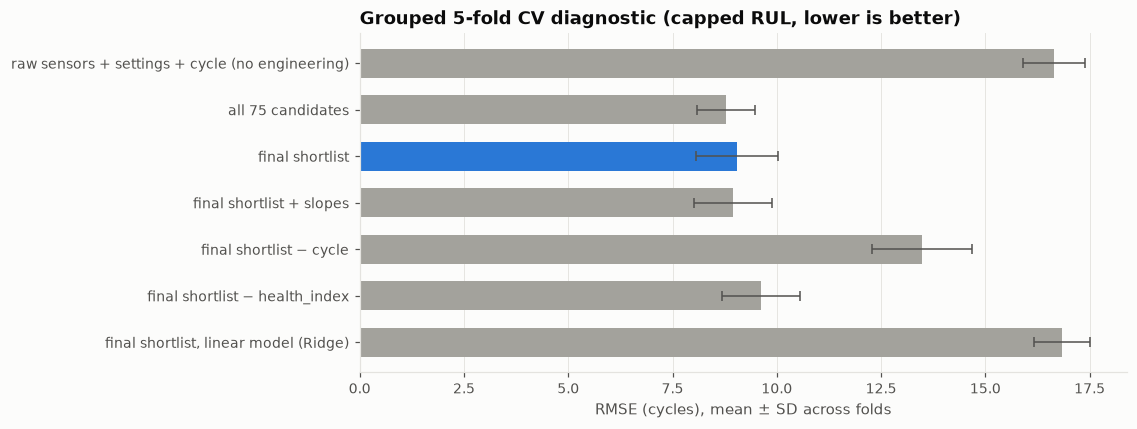

In [52]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_data = diagnostic.iloc[::-1]
colors = [SERIES[0] if name == "final shortlist" else NEUTRAL for name in plot_data.index]
ax.barh(plot_data.index, plot_data["RMSE (mean)"], xerr=plot_data["RMSE (SD across folds)"], color=colors,
        height=0.62, error_kw=dict(ecolor=INK_MUTED, lw=1, capsize=3))
ax.set(title="Grouped 5-fold CV diagnostic (capped RUL, lower is better)", xlabel="RMSE (cycles), mean ± SD across folds")
ax.grid(axis="y", visible=False)
save_figure(fig, "09_feature_set_comparison")
plt.show()

**What does this tell us?**

- **Feature engineering roughly halves the diagnostic error.** Raw sensors give RMSE ≈ 16.7, while the 17-feature shortlist gives ≈ 9.0. The engineered features genuinely help.
- **The shortlist essentially matches all 75 candidates** (9.0 vs 8.8, a difference smaller than the ±0.7–1.0 spread between folds), with under a quarter of the features. Selection removed repetition, not information.
- **Adding the 12 slopes back changes the error by less than 0.1**, well inside the fold-to-fold noise, which confirms the step-2 decision.
- **Removing `cycle` costs about 4.4 RMSE.** Age tells the model whether an engine is still in its long healthy phase, which the sensors cannot show while nothing has drifted yet. It is a legitimate input: an operator always knows an engine's age, and grouped CV confirms it generalises to unseen engines.
- **Removing `health_index` costs about 0.6 RMSE**, a modest gain from the combined indicator. That is smaller than the fold-to-fold spread, so it is suggestive rather than conclusive. It is kept because it is also the most interpretable single summary of engine condition.
- **The linear model is far worse (≈ 16.8) on the same features.** The relationships are strongly non-linear (flat, then accelerating), as Sections 6.1 and 9 showed. The Ridge model was already trained on the capped target, so capping alone does not linearise the problem. Future modelling should use non-linear models, or give linear models explicitly non-linear inputs.

### 9.3 Final shortlist and the reason for every removal

In [53]:
selection_summary = pd.DataFrame({
    "feature": ALL_CANDIDATES,
    "family": relevance["family"].to_numpy(),
    "MI (capped RUL)": relevance["MI (capped RUL)"].round(3).to_numpy(),
    "|Spearman ρ|": relevance["|Spearman ρ| (capped)"].round(3).to_numpy(),
    "selected": [f in FINAL_FEATURES for f in ALL_CANDIDATES],
    "reason": [("selected" if f in FINAL_FEATURES else removal_log[f]) for f in ALL_CANDIDATES],
})
assert selection_summary["reason"].notna().all() and len(removal_log) == len(ALL_CANDIDATES) - len(FINAL_FEATURES)
selection_summary.to_csv(OUTPUT_DIR / "feature_selection_summary.csv", index=False)

display(selection_summary[selection_summary["selected"]].drop(columns="selected").sort_values("MI (capped RUL)", ascending=False))
selection_summary[~selection_summary["selected"]].groupby("reason")["feature"].apply(lambda s: ", ".join(s)).to_frame("removed features")

,feature,family,MI (capped RUL),|Spearman ρ|,reason
74,health_index,health index,0.8260,0.8870,selected
45,Ps30_delta,delta from baseline,0.7560,0.8620,selected
29,T50_delta,delta from baseline,0.7300,0.8510,selected
61,BPR_delta,delta from baseline,0.6850,0.8270,selected
73,W32_delta,delta from baseline,0.6760,0.8280,selected
49,phi_delta,delta from baseline,0.6550,0.8320,selected
69,W31_delta,delta from baseline,0.6420,0.8130,selected
0,cycle,cycle,0.6260,0.7780,selected
42,Ps30_mean10,rolling mean,0.6190,0.7490,selected
33,P30_delta,delta from baseline,0.6160,0.8050,selected


,removed features
reason,
Step 1: no information (MI < 0.02); confirmed by Sections 3.2 / 7,"op_setting_1, op_setting_2, P15"
Step 2: EWM duplicates the rolling mean (median ρ = 0.996); rolling mean kept as the simpler definition,"T24_ewm10, T30_ewm10, T50_ewm10, P30_ewm10, Nf_ewm10, Nc_ewm10, Ps30_ewm10, ..."
"Step 2: raw reading is a noisier version of its rolling mean (median ρ = 0.89, lower MI)","T24, T30, T50, P30, Nf, Nc, Ps30, phi, NRf, NRc, BPR, htBleed, W31, W32"
Step 2: slope family adds no information once levels and deltas are present (diagnostic in 9.2),"T24_slope20, T30_slope20, T50_slope20, P30_slope20, Nf_slope20, Nc_slope20, ..."
Step 3: NRf duplicates Nf (same shaft speed; corrected vs physical at constant inlet conditions),"NRf_mean10, NRf_delta"
Step 3: Nc duplicates NRc (same shaft speed; corrected vs physical at constant inlet conditions),"Nc_mean10, Nc_delta"
"Step 4: |ρ| > 0.9 with Ps30_mean10, which has higher MI","T24_mean10, T30_mean10, T50_mean10, P30_mean10, phi_mean10, BPR_mean10, htBl..."


**Decision: 17 features are kept.**

| Kept | Why |
|---|---|
| `health_index` | Strongest single feature; twelve sensors combined into one low-noise wear indicator |
| 12 × `<sensor>_delta` | Drift from the engine's own baseline; removes initial-wear offsets; each adds partly independent evidence (`NRc_delta` through a non-linear relationship) |
| `Ps30_mean10` | One smoothed *level* representing the ten highly correlated level features |
| `Nf_mean10`, `NRc_mean10` | Speed levels behave differently from the main block (Section 6.7); `NRc` is non-linear and engine-dependent |
| `cycle` | Engine age; places an engine on the healthy-vs-degrading timeline (+4.4 RMSE if removed) |

Every one of the 58 removed features has a recorded reason (table above, saved to `outputs/feature_selection_summary.csv`).

## 10. Categorical encoding

In [54]:
non_numeric = train_features[FINAL_FEATURES].select_dtypes(exclude="number").columns.tolist()
low_cardinality = {f: train_features[f].nunique() for f in FINAL_FEATURES if train_features[f].nunique() <= 20}
print("Non-numeric columns among the final features:", non_numeric or "none")
print("Final features with ≤ 20 distinct values:", low_cardinality or "none")

Non-numeric columns among the final features: none
Final features with ≤ 20 distinct values: none


**No categorical variables requiring encoding were present.** Every feature is a continuous measurement or a quantity derived from one.

Encoding was considered and rejected for the two columns that might *look* categorical:

- **`unit_id`** is an identifier, not a feature. One-hot encoding it would let a model memorise individual training engines, which is useless for new engines and a form of entity leakage. It is used only for grouping.
- **`htBleed`** is integer-valued, but it is an ordered physical quantity (bleed enthalpy) with a meaningful scale, not a category. Encoding it would throw away its ordering. It is also not in the final shortlist except through `htBleed_delta`, which is continuous.

Encoding numeric measurements just to show the technique would make the data worse, so it is not done.

## 11. Numerical scaling

**Why scale.** The final features have very different units and ranges: `cycle` runs to 362, `NRc_mean10` sits around 8,140 rpm, and the deltas are fractions of a unit. Distance-based and gradient-based models (linear models, k-NN, SVMs, neural networks) are sensitive to this. Tree ensembles are not, but a common scale keeps the dataset usable for any model.

**Which scaler.** `StandardScaler` (subtract the mean, divide by the SD). Section 4 established that the extreme values are **genuine degradation**, not errors. A linear rescaling keeps every value and every relative distance, so the tails remain fully visible to a model. We do not clip or winsorise. `RobustScaler` (median/IQR) would be the safer choice if the tails contained errors. Here they are the signal, and both are linear transformations anyway, so the choice changes only the reference point and unit.

**Leakage rule.** The scaler is **fitted on the training engines only**. Its learned means and SDs are then applied unchanged to the test engines. Fitting on test data, even just its means, would pass information about the test distribution into preprocessing.

For future cross-validation, the scaler must be **refitted inside each training fold**, as in the Ridge diagnostic in 9.2, which used a `Pipeline`. The scaler fitted here on *all* training engines is for transforming the held-out test set, not for CV.

In [55]:
scaler = StandardScaler().fit(train_features[FINAL_FEATURES])


def scale_features(df: pd.DataFrame) -> pd.DataFrame:
    scaled = pd.DataFrame(scaler.transform(df[FINAL_FEATURES]), columns=FINAL_FEATURES, index=df.index)
    return pd.concat([df[["unit_id"]], df[["cycle"]].rename(columns={"cycle": "cycle_raw"}), scaled], axis=1)


train_scaled = scale_features(train_features)
test_scaled = scale_features(test_features)

scaler_params = pd.DataFrame({"mean (fitted on train)": scaler.mean_, "SD (fitted on train)": scaler.scale_}, index=FINAL_FEATURES)
scaling_check = pd.DataFrame({
    "train mean": train_scaled[FINAL_FEATURES].mean(),
    "train SD": train_scaled[FINAL_FEATURES].std(ddof=0),
    "test mean": test_scaled[FINAL_FEATURES].mean(),
    "test SD": test_scaled[FINAL_FEATURES].std(ddof=0),
})
assert np.allclose(scaling_check["train mean"], 0, atol=1e-9) and np.allclose(scaling_check["train SD"], 1, atol=1e-9)
assert np.isfinite(train_scaled[FINAL_FEATURES]).all().all() and np.isfinite(test_scaled[FINAL_FEATURES]).all().all()
display(scaler_params)
scaling_check

,mean (fitted on train),SD (fitted on train)
cycle,108.8079,68.8793
T24_delta,0.2949,0.3582
T30_delta,3.5513,4.2643
T50_delta,5.9680,6.8726
P30_delta,-0.5673,0.6734
Nf_mean10,"2,388.0929",0.0618
Nf_delta,0.0375,0.0507
Ps30_mean10,47.5240,0.2351
Ps30_delta,0.1811,0.2091
phi_delta,-0.4834,0.5706


,train mean,train SD,test mean,test SD
cycle,-0.0000,1.0000,-0.4642,0.7703
T24_delta,0.0000,1.0000,-0.4599,0.6099
T30_delta,0.0000,1.0000,-0.4985,0.6123
T50_delta,0.0000,1.0000,-0.4860,0.5818
P30_delta,0.0000,1.0000,0.4476,0.6024
Nf_mean10,0.0000,1.0000,-0.3882,0.7817
Nf_delta,0.0000,1.0000,-0.3898,0.5983
Ps30_mean10,-0.0000,1.0000,-0.4940,0.7028
Ps30_delta,0.0000,1.0000,-0.4515,0.5826
phi_delta,0.0000,1.0000,0.4433,0.5902


**Result and sanity checks.**

- **Training features are exactly standardised** (mean 0, SD 1 to within 10⁻⁹), and there are no NaN or infinite values in either split.
- **Test features are *not* exactly mean 0 / SD 1**, and that is expected: it shows the scaler was fitted on training data only. The shift is systematic and physically sensible. Every feature moves towards the *healthy* side, about 0.25–0.5 SD: features that rise with wear (`health_index`, temperature deltas, `cycle`) have negative test means, and those that fall with wear (`P30`, `phi`, `W31`, `W32` deltas) have positive ones. Test SDs are also below 1. Test engines are cut off before failure, so they are younger, less degraded, and never reach the extreme near-failure values. A test set that came out perfectly standardised would be a warning sign that the scaler had been fitted on it.
- The identifiers `unit_id` and `cycle_raw` (the unscaled cycle, kept for traceability) are **not** scaled and are not model inputs. The scaled `cycle` column is the model input.

**Decision:** `StandardScaler`, fitted on the 100 training engines, applied unchanged to the test engines. The fitted parameters are saved with the final dataset (Section 13) so the transformation can be reproduced exactly.

## 12. Leakage audit

Leakage means information reaching a model that would not be available when the model is actually used. Its effect is always the same: offline scores look better than real-world performance. This dataset has three ways for that to happen: **time** (future cycles), **entity** (other engines, or the same engine on both sides of a split), and **target** (RUL is computed from the failure cycle).

This section collects every safeguard in one place and re-runs the tests on the **final** features of **both** splits.

### 12.1 Feature construction: future information and cross-engine contamination

In [56]:
def feature_leakage_tests(base: pd.DataFrame, built: pd.DataFrame, features: list[str], seed: int) -> pd.Series:
    lifetimes = base.groupby("unit_id")["cycle"].max()
    rng = np.random.default_rng(seed)
    cut = pd.Series(rng.integers(2, lifetimes.to_numpy() + 1), index=lifetimes.index)
    keep = base["cycle"] <= base["unit_id"].map(cut)
    corrupted = base.copy()
    corrupted.loc[~keep, ACTIVE_SENSORS] *= 1000
    diff = lambda rebuilt: float((rebuilt[features] - built.loc[rebuilt.index, features]).abs().max().max())
    return pd.Series({
        "engine isolation": diff(pd.concat([rebuild(e) for _, e in base.groupby("unit_id")])) < FEATURE_TOLERANCE,
        "future truncation": diff(rebuild(base[keep])) < FEATURE_TOLERANCE,
        "future perturbation (×1000)": diff(rebuild(corrupted)[keep]) < FEATURE_TOLERANCE,
    })


construction_audit = pd.DataFrame({
    "train (final features)": feature_leakage_tests(train_df, train_features, FINAL_FEATURES, RANDOM_STATE),
    "test (final features)": feature_leakage_tests(test_df, test_features, FINAL_FEATURES, RANDOM_STATE + 1),
})
assert construction_audit.all().all()
construction_audit

,train (final features),test (final features)
engine isolation,True,True
future truncation,True,True
future perturbation (×1000),True,True


**Result.** All tests pass on both splits. The final features of every engine depend only on that engine's own readings up to the current cycle.

The future-truncation test also rules out **target leakage through the features**. RUL and lifetime are, by definition, information about the future (when the engine will fail). A feature that encoded them in any form, even indirectly, would change when the future cycles are deleted. None does.

### 12.2 Every fitted decision: what data was it learned from?

Preprocessing involves more than the scaler. Every step that *learns something from data* is a potential leak if it sees test data.

In [57]:
fitted_steps = pd.DataFrame([
    ("Constant-column list (3.2)", "train", "dropped from train and test", "7 columns"),
    ("NZV flag for P15 (3.2)", "train", "selection input", "P15"),
    ("IQR fences / spike screen (4)", "train", "analysis only; nothing removed", "—"),
    ("Wear direction d_s (6.3)", "train (within-engine ρ with cycle, no RUL)", "health index for train and test", "12 signs"),
    ("Early-life SD σ_s (8.2)", "train", "health index for train and test", "12 SDs"),
    ("Feature selection (9)", "train (MI, correlation, grouped CV)", "column list for train and test", f"{len(FINAL_FEATURES)} features"),
    ("StandardScaler (11)", "train", "transform train and test", f"{len(FINAL_FEATURES)} means / SDs"),
], columns=["fitted step", "learned from", "applied to", "parameters"])

# Re-derive the fitted parameters from training data alone and confirm they match those used.
refit_scaler = StandardScaler().fit(train_features[FINAL_FEATURES])
refit_hi = fit_health_index(train_df)
assert np.allclose(refit_scaler.mean_, scaler.mean_) and np.allclose(refit_scaler.scale_, scaler.scale_)
assert refit_hi["early_sd"].equals(health_index_params["early_sd"]) and refit_hi["direction"].equals(health_index_params["direction"])
assert CONSTANT_COLUMNS == variance_profile(train_raw, SETTING_COLUMNS + SENSOR_COLUMNS).query("constant").index.tolist()
fitted_steps

,fitted step,learned from,applied to,parameters
0,Constant-column list (3.2),train,dropped from train and test,7 columns
1,NZV flag for P15 (3.2),train,selection input,P15
2,IQR fences / spike screen (4),train,analysis only; nothing removed,—
3,Wear direction d_s (6.3),"train (within-engine ρ with cycle, no RUL)",health index for train and test,12 signs
4,Early-life SD σ_s (8.2),train,health index for train and test,12 SDs
5,Feature selection (9),"train (MI, correlation, grouped CV)",column list for train and test,17 features
6,StandardScaler (11),train,transform train and test,17 means / SDs


**A stricter check for the CV diagnostic.** Within the training set, the health-index parameters were estimated on *all* training engines, so in the grouped CV of 9.2 each validation fold's engines also contributed to them. These parameters never see the target, so the risk is small, but it can be measured. Here they are re-estimated inside every fold from the training-fold engines only:

In [58]:
fold_scores = []
features_without_hi = train_features.drop(columns="health_index")
for train_idx, val_idx in GroupKFold(CV_FOLDS).split(train_features, y_capped, groups=train_features["unit_id"]):
    fold_frame = add_health_index(features_without_hi, fit_health_index(train_df.iloc[train_idx]))
    model = boosting().fit(fold_frame.iloc[train_idx][FINAL_FEATURES], y_capped.iloc[train_idx])
    fold_scores.append(root_mean_squared_error(y_capped.iloc[val_idx], model.predict(fold_frame.iloc[val_idx][FINAL_FEATURES])))
print(f"Health index fitted per fold: RMSE {np.mean(fold_scores):.2f} | fitted on all training engines: "
      f"{diagnostic.loc['final shortlist', 'RMSE (mean)']:.2f}")

Health index fitted per fold: RMSE 8.98 | fitted on all training engines: 9.04


**Result.** All seven fitted steps were learned from training engines only, and re-deriving the parameters from training data alone reproduces exactly the values in use. Fitting the health index inside each fold gives practically the same diagnostic score (8.98 vs 9.04), so sharing those target-free parameters across folds did not inflate the result. The **test labels** (`RUL_FD001.txt`) were used for one thing: checking that the test RUL is built correctly (5.1). They influenced no decision.

### 12.3 Why random row-level splitting is dangerous here

A common mistake with this dataset is to shuffle all rows and split them randomly into train and validation. Neighbouring cycles of the same engine are then on both sides of the split. The model can "predict" a validation row by recognising its almost identical neighbours from training, for example the same engine one cycle earlier with a 10-cycle rolling mean that shares nine of its ten readings. The rolling features make this worse, because adjacent rows share most of their window.

We measure the effect directly. The same model and the same 17 features are evaluated with a random row split and with engine-grouped folds.

In [59]:
from sklearn.model_selection import KFold


def cv_rmse(splitter, features, groups=None) -> float:
    scores = []
    for train_idx, val_idx in splitter.split(train_features, y_capped, groups):
        model = boosting().fit(train_features.iloc[train_idx][features], y_capped.iloc[train_idx])
        scores.append(root_mean_squared_error(y_capped.iloc[val_idx], model.predict(train_features.iloc[val_idx][features])))
    return float(np.mean(scores))


random_rmse = cv_rmse(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE), FINAL_FEATURES)
grouped_rmse = cv_rmse(GroupKFold(CV_FOLDS), FINAL_FEATURES, groups=train_features["unit_id"])
split_comparison = pd.DataFrame({
    "validation RMSE": [random_rmse, grouped_rmse],
    "engines appear on both sides": ["yes (every engine)", "no"],
}, index=["random row-level 5-fold", "engine-grouped 5-fold"])
print(f"Random row splitting understates the error by {100 * (1 - random_rmse / grouped_rmse):.0f}%")
split_comparison

Random row splitting understates the error by 42%


,validation RMSE,engines appear on both sides
random row-level 5-fold,5.2062,yes (every engine)
engine-grouped 5-fold,9.0430,no


**What does this tell us?** For the same model and features, the random split reports **RMSE ≈ 5.2**, while the engine-grouped split reports **≈ 9.0**. Random splitting understates the error by about 42%. That gap is pure optimism: the model is rewarded for recognising engines it has already seen. In deployment, every engine is new: its earlier cycles were never in the training data.

An engine-grouped split answers the real question, "how well does this generalise to an engine we have never seen?". It is the only split used in this notebook (Section 9.2), and the final training file includes a `cv_fold` column that assigns **whole engines** to folds, so future modelling starts from a correct split.

### 12.4 Leakage audit summary

| Risk | Safeguard | Evidence |
|---|---|---|
| Future sensor values in features | Trailing windows only; baseline from the engine's first cycles | Truncation and ×1000 perturbation tests pass on train and test (12.1) |
| Cross-engine contamination | All temporal operations grouped by `unit_id` | Engine-isolation test passes on train and test (12.1) |
| Target leakage | RUL never in a feature list; no lifetime-derived column stored; `assert_no_target_leakage` on every list | Assertions pass; truncation test rules out indirect encodings (12.1) |
| Lifetime-based analysis variables | `life_fraction` and RUL alignment used **only** in analysis charts | No such column exists in any feature frame |
| Preprocessing fitted on test data | Every fitted step learned from training engines | Re-derivation check (12.2) |
| Test labels influencing decisions | Used only to validate the test RUL construction | — |
| Random row-level splitting | Engine-grouped CV only; `cv_fold` assigns whole engines | Random split understates error (12.3) |

**No leakage was found.** One residual, documented risk remains: the feature selection used grouped CV on the same training engines it was evaluated on, so the diagnostic score in 9.2 is mildly optimistic. The untouched test set is where an unbiased score must come from.

## 13. Final ML-ready dataset

### 13.1 Target definition

Two target columns are provided:

| Column | Definition | Role |
|---|---|---|
| **`RUL_capped`** | `min(RUL, 125)` | **Recommended training target** |
| `RUL` | Engine's failure cycle − current cycle (uncapped) | Reference and evaluation |

**Why capped is recommended.** Section 6.5 showed that the sensors show no degradation until about 120–160 cycles before failure. An uncapped target asks a model to distinguish RUL 300 from RUL 200 using features that carry no such information. The model can then only guess the fleet average, and the noise this adds to training is pure error. Capping at 125 says "more than 125 cycles left: healthy", which matches what the data can support. Section 9 also showed that `cycle` looks artificially strong against the uncapped target, because uncapped RUL is built from it.

**What the cap costs.** A model trained on `RUL_capped` can never predict more than 125 cycles. That is acceptable for maintenance planning, where the actionable range is the final ~100 cycles. The uncapped `RUL` is kept so this choice can be revisited. 125 is a defensible value within the evidence range, not a uniquely correct one. Treating the cap as a hyperparameter (e.g. 125–150) during modelling is a natural next step.

For the test set, both columns use the true RUL from `RUL_FD001.txt`. The standard FD001 evaluation scores only each test engine's **last observed cycle**, which is flagged by `is_last_cycle`.

In [60]:
def finalise(features_df: pd.DataFrame, scaled_df: pd.DataFrame, is_train: bool) -> tuple[pd.DataFrame, pd.DataFrame]:
    targets = pd.DataFrame({TARGET: features_df[TARGET], "RUL_capped": features_df[TARGET].clip(upper=RUL_CAP)})
    extra = pd.DataFrame(index=features_df.index)
    if is_train:
        folds = np.empty(len(features_df), dtype="int8")
        for fold, (_, val_idx) in enumerate(GroupKFold(CV_FOLDS).split(features_df, groups=features_df["unit_id"])):
            folds[val_idx] = fold
        extra["cv_fold"] = folds
    else:
        extra["is_last_cycle"] = features_df["cycle"].eq(features_df.groupby("unit_id")["cycle"].transform("max"))
    unscaled = pd.concat([features_df[["unit_id"] + FINAL_FEATURES], targets, extra], axis=1)
    scaled = pd.concat([scaled_df, targets, extra], axis=1)
    return unscaled, scaled


train_final, train_final_scaled = finalise(train_features, train_scaled, is_train=True)
test_final, test_final_scaled = finalise(test_features, test_scaled, is_train=False)
train_final.head()

,unit_id,cycle,T24_delta,T30_delta,T50_delta,P30_delta,Nf_mean10,Nf_delta,Ps30_mean10,Ps30_delta,phi_delta,NRc_mean10,NRc_delta,BPR_delta,htBleed_delta,W31_delta,W32_delta,health_index,RUL,RUL_capped,cv_fold
0,1,1,0.0000,0.0000,0.0000,0.0000,"2,388.0600",0.0000,47.4700,0.0000,0.0000,"8,138.6200",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,191,125,2
1,1,2,0.0165,0.1060,0.1270,-0.0305,"2,388.0500",-0.0010,47.4800,0.0010,0.0310,"8,135.0550",-0.3565,0.0006,0.0000,-0.0030,0.0002,0.0127,190,125,2
2,1,3,0.0349,-0.1268,0.2359,-0.0042,"2,388.0600",0.0015,47.4100,-0.0138,0.0494,"8,134.4467",-0.3385,-0.0002,-0.1373,-0.0073,-0.0052,-0.0029,189,125,2
3,1,4,0.0428,-0.6449,0.0965,0.0232,"2,388.0725",0.0050,47.3400,-0.0315,0.0919,"8,134.2925",-0.2760,-0.0045,-0.0391,-0.0147,-0.0052,-0.0231,188,125,2
4,1,5,0.0481,-0.9147,0.3968,-0.0013,"2,388.0700",0.0024,47.3280,-0.0277,0.0555,"8,134.1940",-0.2396,-0.0014,0.1027,-0.0168,-0.0025,0.0002,187,125,2


### 13.2 Saved artefacts

| File | Contents |
|---|---|
| `data/processed/train_FD001_features.csv` | Training engines: `unit_id`, 17 features (original units), `RUL`, `RUL_capped`, `cv_fold` |
| `data/processed/test_FD001_features.csv` | Test engines: same features and targets, plus `is_last_cycle` |
| `data/processed/train_FD001_scaled.csv`, `test_FD001_scaled.csv` | The same, with features standardised by the training-fitted scaler; `cycle_raw` keeps the unscaled cycle |
| `outputs/scaler_parameters.csv` | Fitted means / SDs, to reproduce or invert the scaling |
| `outputs/feature_summary.csv` | One row per final feature: family, meaning, relevance, scaling parameters |
| `outputs/preprocessing_summary.csv` | Shapes and counts at each stage |
| `outputs/data_quality_report.csv`, `data_dictionary.csv`, `feature_selection_summary.csv` | Saved earlier (Sections 2, 3, 9) |

Use the **unscaled** files with tree models or with any pipeline that fits its own scaler inside CV folds. The scaled files are a convenience for models that need standardised inputs on the full training set.

In [61]:
FEATURE_MEANINGS = {
    "cycle": "Engine age in operating cycles (known at prediction time)",
    "health_index": "Mean wear-aligned drift of 12 consistent sensors from their early-life baseline, in early-life SDs",
}
for s in TEMPORAL_SENSORS:
    FEATURE_MEANINGS[f"{s}_delta"] = f"{SENSOR_DESCRIPTIONS[s]}: EWM (span {EWM_SPAN}) minus the engine's own first-{BASELINE_CYCLES}-cycle mean"
    FEATURE_MEANINGS[f"{s}_mean{ROLL_WINDOW}"] = f"{SENSOR_DESCRIPTIONS[s]}: trailing {ROLL_WINDOW}-cycle mean"

feature_summary = pd.DataFrame({
    "feature": FINAL_FEATURES,
    "family": [family_of(f) if f != "cycle" else "engine age" for f in FINAL_FEATURES],
    "meaning": [FEATURE_MEANINGS[f] for f in FINAL_FEATURES],
    "MI (capped RUL)": relevance.loc[FINAL_FEATURES, "MI (capped RUL)"].round(3).to_numpy(),
    "|Spearman ρ| (capped RUL)": relevance.loc[FINAL_FEATURES, "|Spearman ρ| (capped)"].round(3).to_numpy(),
    "scaler mean": scaler.mean_,
    "scaler SD": scaler.scale_,
})

preprocessing_summary = pd.Series({
    "original training shape": str(train_raw.shape),
    "training shape after cleaning (constant columns dropped)": str(train_clean.shape),
    "final training shape": str(train_final.shape),
    "final test shape": str(test_final.shape),
    "rows removed (duplicates / outliers / missing)": len(train_raw) - len(train_final),
    "raw sensors": len(SENSOR_COLUMNS),
    "sensors retained after quality audit": len(ACTIVE_SENSORS),
    "sensors with a dedicated final feature (more enter via health_index)": len({f.split("_")[0] for f in FINAL_FEATURES} & set(SENSOR_COLUMNS)),
    "constant columns removed": len(CONSTANT_COLUMNS),
    "candidate features evaluated": len(ALL_CANDIDATES),
    "engineered features created": len(ENGINEERED_FEATURES),
    "engineered features in final set": len(set(FINAL_FEATURES) & set(ENGINEERED_FEATURES)),
    "candidate features removed in selection": len(ALL_CANDIDATES) - len(FINAL_FEATURES),
    "final features": len(FINAL_FEATURES),
    "target": f"RUL_capped = min(RUL, {RUL_CAP}); uncapped RUL also provided",
}, name="value")

train_final.to_csv(PROCESSED_DIR / f"train_{SUBSET}_features.csv", index=False)
test_final.to_csv(PROCESSED_DIR / f"test_{SUBSET}_features.csv", index=False)
train_final_scaled.to_csv(PROCESSED_DIR / f"train_{SUBSET}_scaled.csv", index=False)
test_final_scaled.to_csv(PROCESSED_DIR / f"test_{SUBSET}_scaled.csv", index=False)
scaler_params.to_csv(OUTPUT_DIR / "scaler_parameters.csv", index_label="feature")
feature_summary.to_csv(OUTPUT_DIR / "feature_summary.csv", index=False)
preprocessing_summary.to_csv(OUTPUT_DIR / "preprocessing_summary.csv", header=True, index_label="item")

preprocessing_summary.to_frame()

,value
original training shape,"(20631, 26)"
training shape after cleaning (constant columns dropped),"(20631, 19)"
final training shape,"(20631, 21)"
final test shape,"(13096, 21)"
rows removed (duplicates / outliers / missing),0
raw sensors,21
sensors retained after quality audit,15
sensors with a dedicated final feature (more enter via health_index),12
constant columns removed,7
candidate features evaluated,75


In [62]:
feature_summary.drop(columns=["scaler mean", "scaler SD"])

,feature,family,meaning,MI (capped RUL),|Spearman ρ| (capped RUL)
0,cycle,engine age,Engine age in operating cycles (known at prediction time),0.6260,0.7780
1,T24_delta,delta from baseline,Total temperature at LPC outlet: EWM (span 10) minus the engine's own first-...,0.5700,0.7780
2,T30_delta,delta from baseline,Total temperature at HPC outlet: EWM (span 10) minus the engine's own first-...,0.5740,0.7820
3,T50_delta,delta from baseline,Total temperature at LPT outlet: EWM (span 10) minus the engine's own first-...,0.7300,0.8510
4,P30_delta,delta from baseline,Total pressure at HPC outlet: EWM (span 10) minus the engine's own first-10-...,0.6160,0.8050
5,Nf_mean10,rolling mean,Physical fan speed: trailing 10-cycle mean,0.3360,0.5980
6,Nf_delta,delta from baseline,Physical fan speed: EWM (span 10) minus the engine's own first-10-cycle mean,0.4670,0.7120
7,Ps30_mean10,rolling mean,Static pressure at HPC outlet: trailing 10-cycle mean,0.6190,0.7490
8,Ps30_delta,delta from baseline,Static pressure at HPC outlet: EWM (span 10) minus the engine's own first-10...,0.7560,0.8620
9,phi_delta,delta from baseline,Ratio of fuel flow to Ps30: EWM (span 10) minus the engine's own first-10-cy...,0.6550,0.8320


### 13.3 Preprocessing operations, in order

1. **Parsed** whitespace-delimited files with the trailing spaces handled; named the 26 columns from Saxena et al. (2008), Table 2.
2. **Audited** quality: no missing values, duplicates, gaps or invalid values, so **no imputation or de-duplication**.
3. **Dropped 7 constant columns** (identified on training data, applied to both splits).
4. **Analysed outliers**: all extremes are degradation, so **no rows removed, clipped or winsorised**. All 20,631 training rows are kept.
5. **Derived the RUL target** per engine (train: failure cycle − cycle; test: via `RUL_FD001.txt`); added `RUL_capped` (125).
6. **Engineered 57 temporal features** per engine from past and current cycles only (rolling mean, EWM, slope, baseline delta, health index).
7. **Selected 17 features** using MI, correlation, redundancy clustering, domain reasoning and a grouped-CV diagnostic.
8. **No encoding** (no categorical variables).
9. **Standardised** features with a scaler fitted on training engines only.
10. **Assigned engine-grouped CV folds** for future modelling.

## 14. Automated quality control

Final checks on the saved files, read back from disk so that what is tested is exactly what is delivered.

In [63]:
saved = {
    "train": pd.read_csv(PROCESSED_DIR / f"train_{SUBSET}_features.csv"),
    "test": pd.read_csv(PROCESSED_DIR / f"test_{SUBSET}_features.csv"),
    "train_scaled": pd.read_csv(PROCESSED_DIR / f"train_{SUBSET}_scaled.csv"),
    "test_scaled": pd.read_csv(PROCESSED_DIR / f"test_{SUBSET}_scaled.csv"),
}
key = {"train": "cycle", "test": "cycle", "train_scaled": "cycle_raw", "test_scaled": "cycle_raw"}
expected_rows = {"train": len(train_raw), "test": len(test_raw), "train_scaled": len(train_raw), "test_scaled": len(test_raw)}


def qa_checks(name: str, df: pd.DataFrame) -> dict:
    features = df[FINAL_FEATURES]
    by_engine = df.groupby("unit_id")
    checks = {
        "row count unchanged from raw": len(df) == expected_rows[name],
        "no NaN values": not df.isna().any().any(),
        "no infinite values": bool(np.isfinite(df.select_dtypes("number")).all().all()),
        "no object/string columns": df.select_dtypes(exclude="number").columns.difference(["is_last_cycle"]).empty,
        f"exactly {len(FINAL_FEATURES)} features present": list(features.columns) == FINAL_FEATURES,
        "unique (unit_id, cycle) rows": not df.duplicated(["unit_id", key[name]]).any(),
        "RUL non-negative, falls by 1 per cycle": bool((df[TARGET] >= 0).all() and by_engine[TARGET].diff().dropna().eq(-1).all()),
        "RUL_capped = min(RUL, cap)": df["RUL_capped"].equals(df[TARGET].clip(upper=RUL_CAP)),
        "no target-derived feature columns": not LEAKY_COLUMN_NAMES.intersection(FINAL_FEATURES),
        "saved file identical to in-memory frame": np.allclose(
            features.to_numpy(), (train_final_scaled if name == "train_scaled" else test_final_scaled if name == "test_scaled"
                                  else train_final if name == "train" else test_final)[FINAL_FEATURES].to_numpy(), atol=1e-9),
    }
    if name.startswith("train"):
        checks["final training RUL is 0 for every engine"] = bool(by_engine.tail(1)[TARGET].eq(0).all())
        checks["each engine in exactly one CV fold"] = bool(by_engine["cv_fold"].nunique().eq(1).all())
    else:
        checks["one last-cycle row per engine, RUL matches file"] = bool(
            df[df["is_last_cycle"]].set_index("unit_id")[TARGET].sort_index().equals(test_true_rul.set_index("unit_id")["true_rul"].sort_index()))
    if name == "train_scaled":
        checks["scaled train: mean 0, SD 1"] = bool(np.allclose(features.mean(), 0, atol=1e-6) and np.allclose(features.std(ddof=0), 1, atol=1e-6))
    return checks


qa_report = pd.DataFrame({name: qa_checks(name, df) for name, df in saved.items()})
qa_report.loc["feature generation stays within engine boundaries"] = construction_audit.all().all()
qa_display = qa_report.map(lambda v: "—" if pd.isna(v) else ("PASS" if v else "FAIL"))
assert not (qa_display == "FAIL").any().any(), "QA failure"
print(f"QA: {(qa_display == 'PASS').sum().sum()} checks passed, {(qa_display == 'FAIL').sum().sum()} failed")
qa_display

QA: 51 checks passed, 0 failed


,train,test,train_scaled,test_scaled
row count unchanged from raw,PASS,PASS,PASS,PASS
no NaN values,PASS,PASS,PASS,PASS
no infinite values,PASS,PASS,PASS,PASS
no object/string columns,PASS,PASS,PASS,PASS
exactly 17 features present,PASS,PASS,PASS,PASS
"unique (unit_id, cycle) rows",PASS,PASS,PASS,PASS
"RUL non-negative, falls by 1 per cycle",PASS,PASS,PASS,PASS
"RUL_capped = min(RUL, cap)",PASS,PASS,PASS,PASS
no target-derived feature columns,PASS,PASS,PASS,PASS
saved file identical to in-memory frame,PASS,PASS,PASS,PASS


**Final QA report.** Every applicable check passes on every saved file (a dash means the check does not apply to that file). Specifically:

- **Integrity:** no NaN, no infinite values and no string columns; every raw row is present; `(unit_id, cycle)` is unique.
- **Target:** RUL is non-negative and falls by one per cycle; training engines end at 0; test engines end at the values in `RUL_FD001.txt`; `RUL_capped` is exactly `min(RUL, 125)`.
- **Features:** exactly the 17 shortlisted features, in a fixed order; no target-derived columns; generation verified within engine boundaries (12.1).
- **Scaling:** the saved scaled training features have mean 0 and SD 1.
- **Reproducibility:** the files read back from disk match the in-memory results.

**The dataset is ready for modelling.**